# Heurística de validación de fase — segmentación, perfil y delta de fase

Issue: [#8](https://github.com/Jacogz/DL-QPI/issues/8)

**Objetivo:** post-procesamiento de imágenes de fase para extraer métricas de validación de eritrocitos generados por el CycleGAN.

**Entregables:**
1. Segmentación de eritrocitos individuales en imágenes de fase (SAM).
2. Cálculo del perfil de fase y el delta de fase de cada eritrocito segmentado.
3. Visualización de la reconstrucción de cada eritrocito individual.
4. Anotación sobre las imágenes de fase con el perfil y delta de fase promedio.

**Requiere:** haber ejecutado `04-limpieza-fases-rbc.ipynb`, cuyo ZIP de salida (`rbc_fases_processed.zip`) debe estar en Google Drive.

---

### Nota sobre la escala de los valores de fase

Como se documentó en la sección 0.5 del notebook 04, los PNG de fase están **normalizados por recorte** (min-max de 0 a 255), no en escala fija $[-\pi, \pi]$. Por lo tanto, el delta de fase se reporta en **unidades relativas** (niveles de gris 0–255), no en radianes.

## 0. Setup

In [18]:
# Instalar SAM (Segment Anything Model)
!pip install -q segment-anything

# Descargar checkpoint SAM ViT-B (aprox 375 MB) suficiente para parches 256×256
import os
SAM_CKPT = 'sam_vit_b_01ec64.pth'
if not os.path.exists(SAM_CKPT):
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
    print(f'Descargado: {SAM_CKPT}')
else:
    print(f'Ya existe: {SAM_CKPT}')

Ya existe: sam_vit_b_01ec64.pth


In [19]:
import json
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy import ndimage as ndi
from skimage import measure
from tqdm.auto import tqdm

from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

print(f'PyTorch {torch.__version__}, CUDA disponible: {torch.cuda.is_available()}')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Dispositivo: {DEVICE}')

PyTorch 2.14.1+cu130, CUDA disponible: True
Dispositivo: cuda


## 1. Carga de datos desde Drive

In [20]:
from google.colab import drive
drive.mount('/content/drive')

# Rutas
DRIVE_ZIP = Path('/content/drive/MyDrive/dl-qpi/data/processed/rbc_fases_processed.zip')
DATA_DIR  = Path('/content/data/processed/rbc_fases_processed')

# Descomprimir si no existe ya
if not DATA_DIR.is_dir():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP, 'r') as zf:
        zf.extractall(DATA_DIR)
    print(f'Descomprimido en {DATA_DIR}')
else:
    print(f'Ya existe: {DATA_DIR}')

# Buscar manifest.csv (puede estar en la raíz o un nivel adentro)
manifest_candidates = list(DATA_DIR.rglob('manifest.csv'))
assert manifest_candidates, f'No se encontró manifest.csv en {DATA_DIR}'
MANIFEST_PATH = manifest_candidates[0]
IMG_ROOT = MANIFEST_PATH.parent  # las rutas en manifest son relativas a esta carpeta
print(f'Manifest: {MANIFEST_PATH}')
print(f'Raíz de imágenes: {IMG_ROOT}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ya existe: /content/data/processed/rbc_fases_processed
Manifest: /content/data/processed/rbc_fases_processed/manifest.csv
Raíz de imágenes: /content/data/processed/rbc_fases_processed


In [21]:
# Cargar manifiesto
manifest = pd.read_csv(MANIFEST_PATH)
manifest['cell_boxes'] = manifest['cell_boxes'].apply(json.loads)
manifest['n_cells'] = manifest['cell_boxes'].apply(len)

print(f'Recortes totales: {len(manifest)}')
print(manifest.groupby('split').agg(
    recortes=('file', 'size'),
    celulas_mediana=('n_cells', 'median')
))
manifest.head()

Recortes totales: 2734
            recortes  celulas_mediana
split                                
Training        2292              6.0
Validation       442              6.0


,file,split,source,a,b,split_paper,file_paper,bg_gray,n_cells,cell_boxes
0,Training/Image__2021-01-28__15-49-02_1-10.png,Training,Image__2021-01-28__15-49-02,1,10,Training,Image__2021-01-28__15-49-02_1-10.png.png.png,129.0,4,"[[13, 139, 67, 191], [123, 173, 176, 224], [20..."
1,Training/Image__2021-01-28__15-49-02_1-13.png,Training,Image__2021-01-28__15-49-02,1,13,Training,Image__2021-01-28__15-49-02_1-13.png.png.png,109.0,5,"[[20, 137, 68, 186], [42, 0, 91, 21], [136, 38..."
2,Training/Image__2021-01-28__15-49-02_1-14.png,Training,Image__2021-01-28__15-49-02,1,14,Training,Image__2021-01-28__15-49-02_1-14.png.png.png,149.0,3,"[[0, 0, 256, 256], [150, 81, 197, 126], [203, ..."
3,Training/Image__2021-01-28__15-49-02_1-2.png,Training,Image__2021-01-28__15-49-02,1,2,Training,Image__2021-01-28__15-49-02_1-2.png.png.png,90.0,3,"[[0, 108, 45, 156], [50, 191, 105, 245], [175,..."
4,Training/Image__2021-01-28__15-49-02_1-4.png,Training,Image__2021-01-28__15-49-02,1,4,Training,Image__2021-01-28__15-49-02_1-4.png.png.png,116.0,5,"[[24, 175, 80, 226], [26, 234, 73, 256], [120,..."


In [22]:
# Seleccionar ≥ 5 imágenes de muestra con buen número de células
SEED = 42
N_SAMPLE = 8  # usar 8 para tener margen, mínimo 5

# Filtrar imágenes con al menos 2 células (para que el perfil sea interesante)
candidates = manifest[manifest['n_cells'] >= 2].copy()
sample_df = candidates.sample(n=min(N_SAMPLE, len(candidates)), random_state=SEED)
sample_df = sample_df.reset_index(drop=True)

print(f'Imágenes seleccionadas: {len(sample_df)}')
for i, row in sample_df.iterrows():
    print(f'  [{i}] {row["file"]}  ({row["n_cells"]} células detectadas en nb04)')

Imágenes seleccionadas: 8
  [0] Training/Image__2021-01-29__12-36-21_4-3.png  (5 células detectadas en nb04)
  [1] Training/Image__2021-01-29__13-12-01_4-1.png  (4 células detectadas en nb04)
  [2] Training/Image__2021-01-29__13-26-59_3-8.png  (5 células detectadas en nb04)
  [3] Training/Image__2021-01-29__13-12-01_4-11.png  (3 células detectadas en nb04)
  [4] Training/Image__2021-01-29__13-12-45_2-1.png  (2 células detectadas en nb04)
  [5] Training/Image__2021-01-28__16-04-31_3-3.png  (4 células detectadas en nb04)
  [6] Validation/Image__2021-01-29__13-15-19_3-6.png  (9 células detectadas en nb04)
  [7] Training/Image__2021-01-29__12-53-41_1-6.png  (8 células detectadas en nb04)


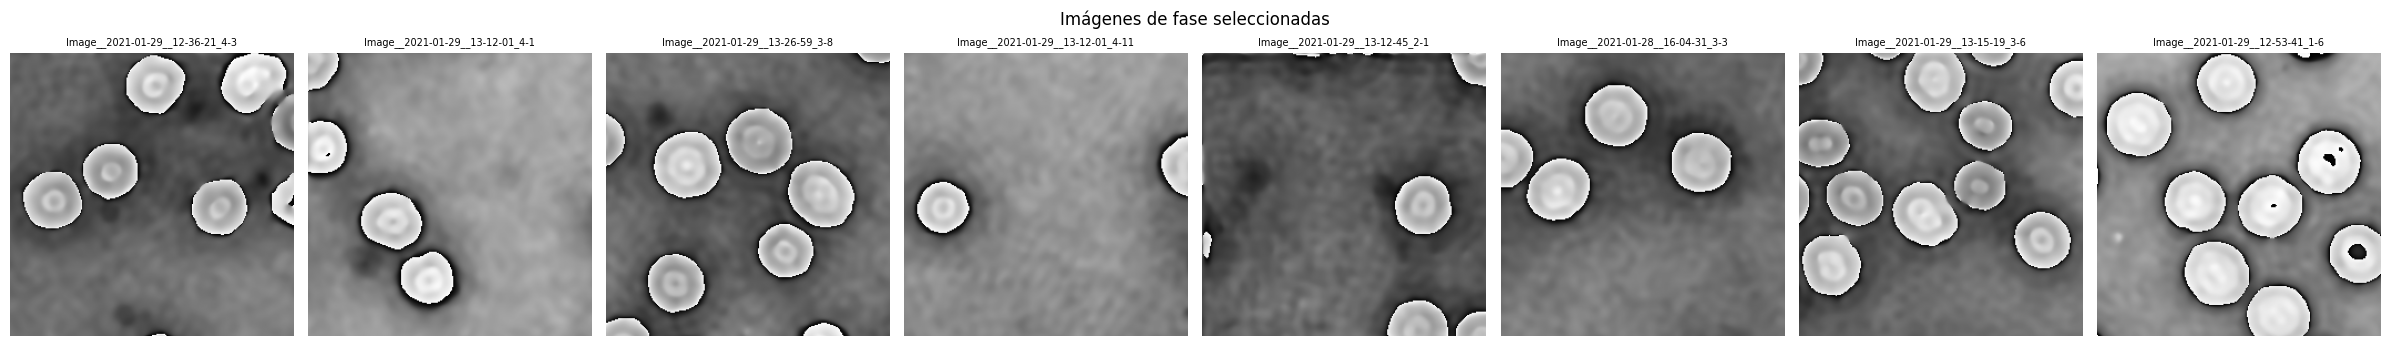

In [23]:
# Vista rápida de las imágenes seleccionadas
n = len(sample_df)
fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.5), squeeze=False)
for i, (_, row) in enumerate(sample_df.iterrows()):
    img = np.array(Image.open(IMG_ROOT / row['file']).convert('L'))
    axes[0][i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[0][i].set_title(Path(row['file']).stem, fontsize=7)
    axes[0][i].axis('off')
plt.suptitle('Imágenes de fase seleccionadas', fontsize=12)
plt.tight_layout()
plt.show()

## 2. Inicializar SAM

In [24]:
sam = sam_model_registry['vit_b'](checkpoint=SAM_CKPT)
sam = sam.to(DEVICE)
sam.eval()

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,          # densidad de la grilla de prompts
    pred_iou_thresh=0.80,        # umbral de confianza de IoU (de 0.80 para capturar células de borde)
    stability_score_thresh=0.85, # estabilidad de la máscara (de 0.85 para incluir células parciales)
    min_mask_region_area=150,    #  área mínima en píxeles (de 150 para fragmentos de borde)
)
print('SAM inicializado correctamente.')


SAM inicializado correctamente.


## 3. Funciones auxiliares

In [25]:
# Conversión de intensidad a fase (relativa)
# Los PNG están normalizados min-max por recorte (ver notebook 04, sección 0.5)
# Mapeamos 0–255 a [-1, 1] para el cálculo de perfiles, como se acordó para el DataLoader

def to_phase(gray: np.ndarray) -> np.ndarray:
    """Convierte imagen 8-bit (0–255) a fase aproximada en radianes [−π, π]."""
    return gray.astype(np.float64) / 255.0 * 2.0 * np.pi - np.pi


def to_phase_norm(gray: np.ndarray) -> np.ndarray:
    """Convierte imagen 8-bit a [0, 1] para visualización."""
    return gray.astype(np.float64) / 255.0


In [26]:
# Filtrado de máscaras SAM

# Qué corrige:
#  1. Mismo eritrocito con 2 etiquetas  NMS por solapamiento (gana la máscara más grande).
#  2. Eliminación de segmentación de la barriguita (zona central)
#  3. Eritrocitos que no se toman  sin filtro de picos, área máx. 5000,
#     huecos rellenados (los puntos negros ya no rompen la solidez) y recuperación por Otsu
#     de células que SAM no segmentó o que fueron descartadas
#  4. Dos eritrocitos tomados como uno se deja solo la componente conexa más grande
#     y se descartan máscaras fusionadas con la razón DT/radio equivalente

from skimage.filters import threshold_otsu


def _contour(mask):
    contours, _ = cv2.findContours(
        mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return max(contours, key=cv2.contourArea) if contours else None


def circularity(mask: np.ndarray) -> float:
    """Circularidad (1.0 = círculo perfecto)."""
    c = _contour(mask)
    if c is None:
        return 0.0
    per = cv2.arcLength(c, True)
    return 4 * np.pi * cv2.contourArea(c) / per ** 2 if per > 0 else 0.0


def solidity(mask: np.ndarray) -> float:
    """Solidez = área / área del casco convexo."""
    c = _contour(mask)
    if c is None:
        return 0.0
    hull = cv2.contourArea(cv2.convexHull(c))
    return cv2.contourArea(c) / hull if hull > 0 else 0.0


def aspect_ratio(mask: np.ndarray) -> float:
    """Eje mayor / eje menor."""
    c = _contour(mask)
    if c is None or len(c) < 5:
        return 999.0
    (_, _), (w, h), _ = cv2.fitEllipse(c)
    return max(w, h) / min(w, h) if min(w, h) > 0 else 999.0


def equiv_diameter(mask: np.ndarray) -> float:
    return float(np.sqrt(4.0 * mask.sum() / np.pi))


def touches_border(mask: np.ndarray, margin: int = 2) -> bool:
    return bool(mask[:margin, :].any() or mask[-margin:, :].any() or
                mask[:, :margin].any() or mask[:, -margin:].any())


def phase_contrast(mask: np.ndarray, phase_img: np.ndarray, dilate_px: int = 12) -> float:
    """media_dentro - media_anillo_exterior (eritrocito real -> positivo)."""
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate_px + 1,) * 2)
    ring = cv2.dilate(mask.astype(np.uint8), k).astype(bool) & ~mask
    if ring.sum() < 10 or mask.sum() < 10:
        return 0.0
    return float(phase_img[mask].mean() - phase_img[ring].mean())


def clean_mask(seg: np.ndarray) -> np.ndarray:
    """Rellena huecos y se queda con la componente conexa más grande.
    (Una máscara de SAM puede venir en 2 pedazos: célula + vecina)."""
    seg = ndi.binary_fill_holes(seg)
    lab, n = ndi.label(seg)
    if n > 1:
        sizes = ndi.sum(seg, lab, range(1, n + 1))
        seg = lab == (1 + int(np.argmax(sizes)))
    return seg


def fill_ratio(mask: np.ndarray) -> float:
    """max(transformada de distancia) / radio equivalente.
    ≈1 para un disco, ≈0.7 para dos discos pegados (célula fusionada)."""
    r_eq = np.sqrt(mask.sum() / np.pi)
    if r_eq == 0:
        return 0.0
    dt = cv2.distanceTransform(np.pad(mask, 1).astype(np.uint8), cv2.DIST_L2, 5)
    return float(dt.max() / r_eq)


def foreground_mask(phase_img: np.ndarray) -> np.ndarray:
    """Primer plano por Otsu (suavizado), con huecos rellenos (barriguita y puntos negros)."""
    g = ndi.gaussian_filter(phase_img, 1.5)
    lo, hi = np.percentile(g, [2, 98])          # ignora halos negros extremos
    t = threshold_otsu(np.clip(g, lo, hi))
    fg = ndi.binary_fill_holes(g > t)
    return ndi.binary_opening(fg, iterations=2)


def remove_overlapping_masks(masks: list, overlap_thresh: float = 0.60) -> list:
    """NMS por solapamiento: si dos máscaras comparten ≥60 % de la más pequeña,
    gana la MÁS GRANDE (el eritrocito completo gana a la barriguita y a las
    duplicadas). Las fusiones ya fueron descartadas antes de llegar aquí."""
    keep = []
    for m in sorted(masks, key=lambda m: int(m['segmentation'].sum()), reverse=True):
        seg = m['segmentation']
        a = int(seg.sum())
        dup = False
        for k in keep:
            inter = int(np.logical_and(seg, k['segmentation']).sum())
            if inter / max(1, min(a, int(k['segmentation'].sum()))) >= overlap_thresh:
                dup = True
                break
        if not dup:
            keep.append(m)
    return keep


def filter_cell_masks(
    sam_masks: list,
    phase_img: np.ndarray = None,
    min_area: int = 300,
    max_area: int = 5000,          # mayor de 3500: había eritrocitos de ~70 px de diámetro
    # Interior
    min_circ: float = 0.70,
    min_solidity: float = 0.88,    # tras rellenar huecos ya no hace falta 0.91
    max_aspect: float = 1.45,
    min_fill_ratio: float = 0.78,  # < esto  aprox dos células pegadas
    # Borde (células cortadas por el recorte)
    border_min_area: int = 400,
    border_min_circ: float = 0.30,
    border_min_solidity: float = 0.80,
    border_max_aspect: float = 2.0,
    # Contraste / primer plano
    min_phase_contrast: float = 0.0,
    min_fg_fraction: float = 0.85,  # % de la máscara que debe caer en primer plano
    #  Dedup
    overlap_thresh: float = 0.60,
    #  Recuperación
    recover_missing: bool = True,
    verbose: bool = True,
) -> list:
    n_rej = dict(area=0, forma=0, fusion=0, contraste=0, fondo=0)
    fg = foreground_mask(phase_img) if phase_img is not None else None
    valid = []

    def evaluate(m):
        """Devuelve (máscara_limpia | None, motivo_rechazo | None)."""
        seg = clean_mask(m['segmentation'])
        area = int(seg.sum())
        brd = touches_border(seg)
        if not ((border_min_area if brd else min_area) <= area <= max_area):
            return None, 'area'
        c, s, ar = circularity(seg), solidity(seg), aspect_ratio(seg)
        if brd:
            if c < border_min_circ or s < border_min_solidity or ar > border_max_aspect:
                return None, 'forma'
        else:
            if c < min_circ or s < min_solidity or ar > max_aspect:
                return None, 'forma'
            if fill_ratio(seg) < min_fill_ratio:
                return None, 'fusion'
        if phase_img is not None:
            if phase_contrast(seg, phase_img) < min_phase_contrast:
                return None, 'contraste'
            if fg is not None and (fg[seg].mean() < min_fg_fraction):
                return None, 'fondo'
        return seg, None

    for m in sam_masks:
        seg, why = evaluate(m)
        if seg is None:
            n_rej[why] += 1
        else:
            valid.append({**m, 'segmentation': seg, 'source': 'sam'})

    pre = len(valid)
    valid = remove_overlapping_masks(valid, overlap_thresh)
    n_dedup = pre - len(valid)

    # Recuperar células que SAM no entregó (o que se descartaron)
    n_recovered = 0
    if recover_missing and fg is not None:
        covered = np.zeros_like(fg)
        for m in valid:
            covered |= m['segmentation']
        lab, n = ndi.label(fg)
        for i in range(1, n + 1):
            comp = lab == i
            if (comp & covered).sum() / comp.sum() > 0.2:   # ya hay célula ahí
                continue
            cand, why = evaluate({'segmentation': comp})
            if cand is not None:
                valid.append({'segmentation': cand, 'source': 'otsu'})
                n_recovered += 1

    if verbose:
        print(f'    Rechazadas: ' + ', '.join(f'{k}={v}' for k, v in n_rej.items()))
        print(f'    Dedup (mismo eritrocito / barriguita): -{n_dedup} | '
              f'recuperadas por Otsu: +{n_recovered}')
    return valid


In [27]:
# Reparación de huecos por envolvimiento de fase (wrap)
# Los puntos negros dentro de un eritrocito son píxeles cuya fase superó +π y se
# envolvió a −π (gris ≈ 0). Se corrigen sumando 2π, que recupera el valor continuo

WRAP_LOW = 0.7 * np.pi     # candidato: píxel muy por debajo de la mediana de la célula
WRAP_JUMP = 0.7 * np.pi    # salto mínimo entre el hueco y su anillo para llamarlo "wrap"


def repair_wrapped_spots(phi: np.ndarray, mask: np.ndarray, border_px: int = 3):
    """Devuelve (phi_reparada, n_pixeles_reparados). Solo busca DENTRO de la máscara
    (erosionada border_px) para no tocar el halo oscuro real del borde de la célula."""
    inner = ndi.binary_erosion(mask, iterations=border_px)
    if not inner.any():
        return phi, 0
    cell_med = np.median(phi[mask])
    lab, n = ndi.label((phi < cell_med - WRAP_LOW) & inner)
    fixed, n_fix = phi.copy(), 0
    for i in range(1, n + 1):
        comp = lab == i
        if comp.sum() < 2:
            continue
        ring = ndi.binary_dilation(comp, iterations=2) & ~ndi.binary_dilation(comp, iterations=1) & mask
        if ring.sum() < 4:
            continue
        ring_med = np.median(phi[ring])
        if ring_med - np.median(phi[comp]) < WRAP_JUMP:      # caída suave - depresión real
            continue
        grow = ndi.binary_dilation(comp, iterations=1) & mask & (phi < ring_med - 0.4 * np.pi)
        cand = phi + 2 * np.pi
        ok = np.abs(cand - ring_med) < np.pi
        fixed[grow & ok] = cand[grow & ok]
        fixed[grow & ~ok] = ring_med
        n_fix += int(grow.sum())
    return fixed, n_fix


# Extracción de perfil de fase

def extract_phase_profile(phi: np.ndarray, mask: np.ndarray):
    """
    Extrae el perfil de fase a lo largo del diámetro horizontal del eritrocito.

    Parámetros
    ----------
    phi : ndarray
        Imagen de fase completa (valores en [-1, 1]).
    mask : ndarray (bool)
        Máscara binaria de un eritrocito individual.

    Retorna
    -------
    profile : ndarray 1-D
        Valores de fase corregidos por fondo a lo largo del diámetro.
    delta_phi : float
        Diferencia máx – mín del perfil.
    centroid : tuple (cy, cx)
        Coordenadas del centroide de la máscara.
    bg_value : float
        Valor mediano del fondo usado para la corrección.
    """
    # Centroide
    moments = cv2.moments(mask.astype(np.uint8))
    if moments['m00'] == 0:
        return np.array([]), 0.0, (0, 0), 0.0
    cy = int(moments['m01'] / moments['m00'])
    cx = int(moments['m10'] / moments['m00'])

    # Fondo: mediana de la fase fuera de todas las células (se pasa phi completa)
    bg_value = np.median(phi[~mask])

    # Perfil horizontal en la fila del centroide, solo dentro de la máscara
    row_vals = phi[cy, :]
    row_mask = mask[cy, :]
    profile = row_vals[row_mask] - bg_value

    delta_phi = float(profile.max() - profile.min()) if len(profile) > 2 else 0.0

    return profile, delta_phi, (cy, cx), bg_value


def extract_phase_profile_bg_global(phi: np.ndarray, cell_mask: np.ndarray, all_cells_mask: np.ndarray):
    """
    Igual que extract_phase_profile pero usa una máscara global de todas las
    células para calcular el fondo (más preciso cuando hay varias células).
    """
    moments = cv2.moments(cell_mask.astype(np.uint8))
    if moments['m00'] == 0:
        return np.array([]), 0.0, (0, 0), 0.0
    cy = int(moments['m01'] / moments['m00'])
    cx = int(moments['m10'] / moments['m00'])

    # Fondo: mediana fuera de todas las células
    bg_pixels = phi[~all_cells_mask]
    bg_value = np.median(bg_pixels) if len(bg_pixels) > 0 else 0.0

    # Perfil horizontal
    row_vals = phi[cy, :]
    row_mask = cell_mask[cy, :]
    profile = row_vals[row_mask] - bg_value

    delta_phi = float(profile.max() - profile.min()) if len(profile) > 2 else 0.0

    return profile, delta_phi, (cy, cx), bg_value

In [28]:
# Visualización individual de un eritrocito

def plot_cell_panel(
    phi: np.ndarray,
    mask: np.ndarray,
    profile: np.ndarray,
    delta_phi: float,
    centroid: tuple,
    cell_id: int,
    img_name: str,
):
    """
    Muestra un panel de 3 columnas para un eritrocito:
      - Izquierda: recorte de fase con contorno de la máscara.
      - Centro: mapa de fase aislado del eritrocito.
      - Derecha: perfil de fase 1-D con delta anotado.
    """
    cy, cx = centroid
    y_idx, x_idx = np.where(mask)
    pad = 10
    r0, r1 = max(0, y_idx.min() - pad), min(phi.shape[0], y_idx.max() + pad)
    c0, c1 = max(0, x_idx.min() - pad), min(phi.shape[1], x_idx.max() + pad)

    crop_phi = phi[r0:r1, c0:c1]
    crop_mask = mask[r0:r1, c0:c1]

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    # Panel 1: fase + contorno
    axes[0].imshow(crop_phi, cmap='inferno')
    axes[0].contour(crop_mask.astype(np.uint8), levels=[0.5], colors='lime', linewidths=1.5)
    axes[0].set_title(f'Eritrocito {cell_id}\n{img_name}', fontsize=9)
    axes[0].axis('off')

    # Panel 2: fase aislada
    phi_isolated = np.where(crop_mask, crop_phi, np.nan)
    axes[1].imshow(phi_isolated, cmap='inferno')
    axes[1].set_title('Fase aislada', fontsize=9)
    axes[1].axis('off')

    # Panel 3: perfil 1-D
    if len(profile) > 2:
        x_px = np.arange(len(profile))
        axes[2].plot(x_px, profile, color='steelblue', lw=1.5, label='Perfil')
        axes[2].axhline(profile.max(), color='red', ls='--', lw=0.8, label=f'máx = {profile.max():.3f}')
        axes[2].axhline(profile.min(), color='blue', ls='--', lw=0.8, label=f'mín = {profile.min():.3f}')
        axes[2].fill_between(x_px, profile.min(), profile, alpha=0.15, color='steelblue')
        axes[2].set_title(f'Perfil de fase — Δφ = {delta_phi:.4f}', fontsize=9)
        axes[2].set_xlabel('Píxel (diámetro)')
        axes[2].set_ylabel('φ (rad, corregida por fondo)')
        axes[2].legend(fontsize=7, loc='best')
    else:
        axes[2].text(0.5, 0.5, 'Perfil insuficiente\n(< 3 px)', ha='center', va='center', fontsize=10)
        axes[2].set_title('Perfil de fase — sin datos')

    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [29]:
# Anotación de imagen completa

def annotate_image(
    phi: np.ndarray,
    cell_masks: list,
    deltas: list,
    profiles: list,
    centroids: list,
    img_name: str,
    save_dir: Path = None,
    is_border: list = None,
):
    """
    Genera una imagen anotada con contornos numerados y un panel lateral
    con el perfil de fase promedio y el delta promedio.
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                             gridspec_kw={'width_ratios': [1, 0.8]})

    # Panel izquierdo: imagen anotada
    ax_img = axes[0]
    ax_img.imshow(phi, cmap='inferno')

    colors = plt.cm.Set1(np.linspace(0, 1, max(len(cell_masks), 1)))
    for i, (m, dp) in enumerate(zip(cell_masks, deltas)):
        seg = m['segmentation'].astype(np.uint8)
        contours_cv, _ = cv2.findContours(seg, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours_cv:
            pts = cnt.squeeze()
            if pts.ndim == 2 and len(pts) >= 3:
                polygon = plt.Polygon(pts, fill=False,
                                      edgecolor=colors[i % len(colors)],
                                      linewidth=2)
                ax_img.add_patch(polygon)
        cy, cx = centroids[i]
        ax_img.text(cx, cy, str(i + 1), color='white', fontsize=8,
                    ha='center', va='center',
                    bbox=dict(boxstyle='round,pad=0.2', fc='black', alpha=0.6))

    # Estadística solo con células interiores (las de borde están cortadas y su perfil es poco fiable)
    flags = is_border if is_border is not None else [False] * len(deltas)
    d_stat = [d for d, b in zip(deltas, flags) if not b] or list(deltas)
    mean_delta = np.mean(d_stat) if d_stat else 0.0
    std_delta = np.std(d_stat) if len(d_stat) > 1 else 0.0
    ax_img.set_title(
        f'{img_name}\n'
        f'n = {len(cell_masks)} células ({len(d_stat)} interiores) | '
        f'Δφ prom = {mean_delta:.4f} ± {std_delta:.4f}',
        fontsize=10
    )
    ax_img.axis('off')

    # Panel derecho: perfil de fase promedio
    ax_prof = axes[1]
    if profiles:
        # Interpolar todos los perfiles a la misma longitud para promediar
        max_len = max(len(p) for p in profiles)
        interp_profiles = []
        for p in profiles:
            if len(p) > 2:
                x_orig = np.linspace(0, 1, len(p))
                x_new = np.linspace(0, 1, max_len)
                interp_profiles.append(np.interp(x_new, x_orig, p))
        if interp_profiles:
            stacked = np.array(interp_profiles)
            mean_profile = stacked.mean(axis=0)
            std_profile = stacked.std(axis=0)
            x_px = np.arange(max_len)

            # Perfiles individuales (transparentes)
            for j, ip in enumerate(interp_profiles):
                ax_prof.plot(x_px, ip, color=colors[j % len(colors)],
                             alpha=0.3, lw=0.8)

            # Promedio ± std
            ax_prof.plot(x_px, mean_profile, color='black', lw=2, label='Promedio')
            ax_prof.fill_between(x_px,
                                 mean_profile - std_profile,
                                 mean_profile + std_profile,
                                 alpha=0.2, color='gray', label='± 1 std')
            ax_prof.legend(fontsize=8)
            ax_prof.set_title(f'Perfil promedio\nΔφ prom = {mean_delta:.4f}', fontsize=10)
        else:
            ax_prof.text(0.5, 0.5, 'Sin perfiles válidos', ha='center', va='center')
            ax_prof.set_title('Perfil promedio')
    else:
        ax_prof.text(0.5, 0.5, 'Sin células detectadas', ha='center', va='center')
        ax_prof.set_title('Perfil promedio')

    ax_prof.set_xlabel('Posición normalizada (diámetro)')
    ax_prof.set_ylabel('φ (rad)')

    plt.tight_layout()

    if save_dir is not None:
        save_dir.mkdir(parents=True, exist_ok=True)
        save_path = save_dir / f'annotated_{Path(img_name).stem}.png'
        fig.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f'  Guardado: {save_path}')

    plt.show()
    plt.close(fig)

    return mean_delta, std_delta

## 4. Segmentación y análisis — loop principal

Para cada imagen de muestra:
1. Se ejecuta SAM para generar máscaras automáticas.
2. Se filtran las máscaras por área, circularidad y contacto con el borde.
3. Se calcula el fondo global (mediana fuera de todas las células) y se extrae el perfil de fase por eritrocito.
4. Se muestra el panel individual por célula.
5. Se genera la imagen anotada con promedios.


Imagen 1/8: Image__2021-01-29__12-36-21_4-3.png
    Rechazadas: area=11, forma=2, fusion=0, contraste=0, fondo=2
    Dedup (mismo eritrocito / barriguita): -4 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 25
  Eritrocitos válidos: 6


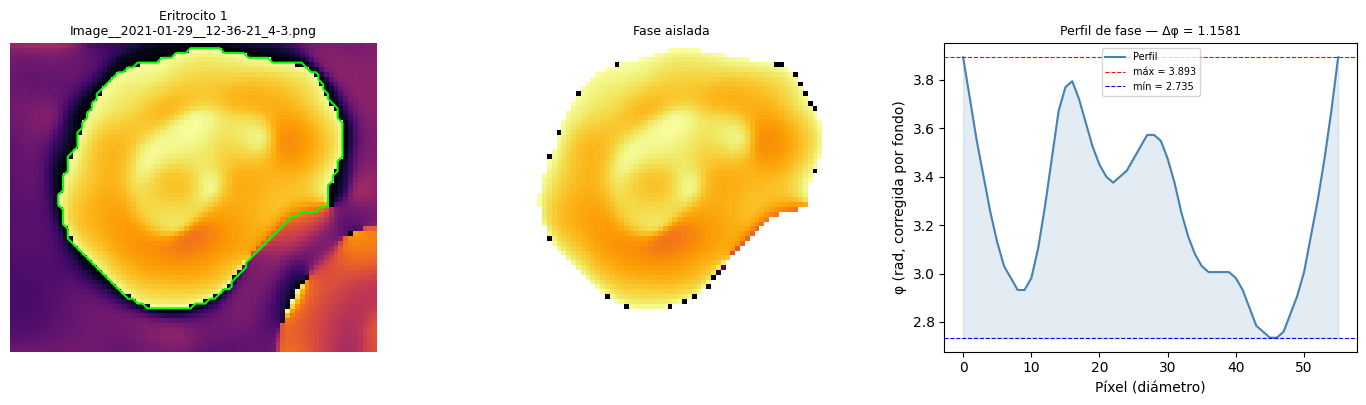

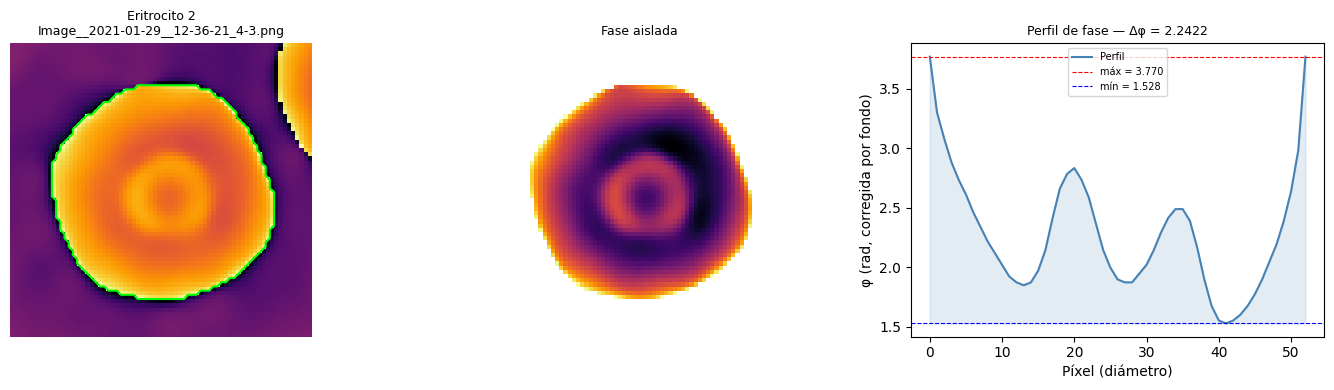

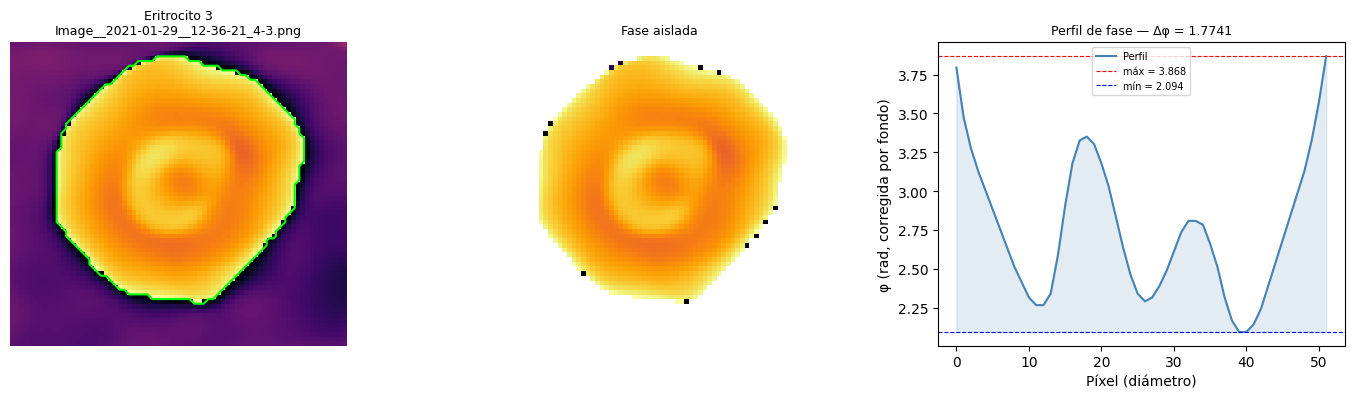

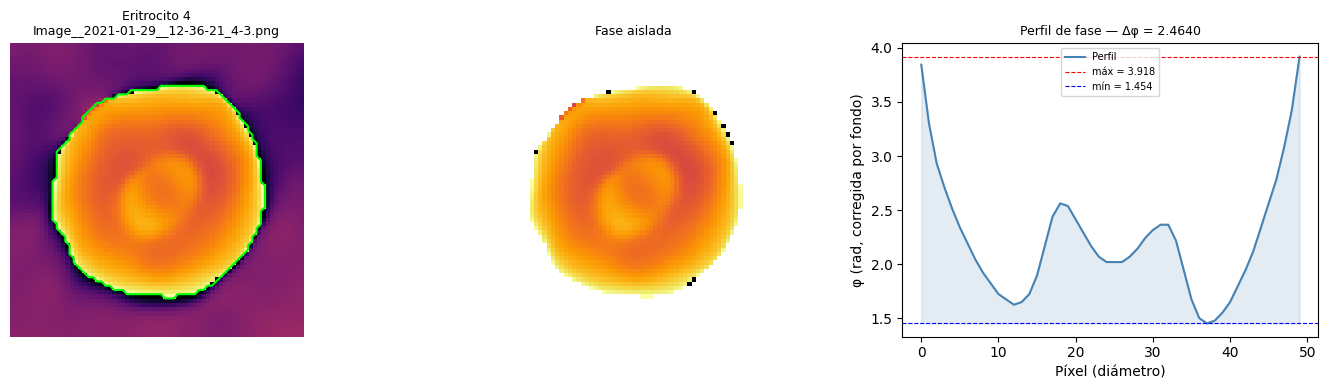

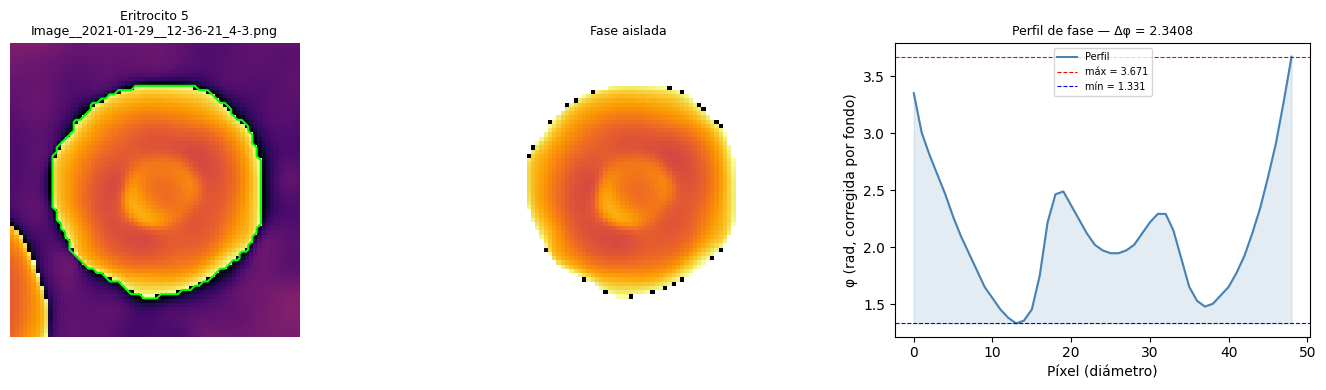

    Célula 6: 10 px de wrap reparados (+2π)


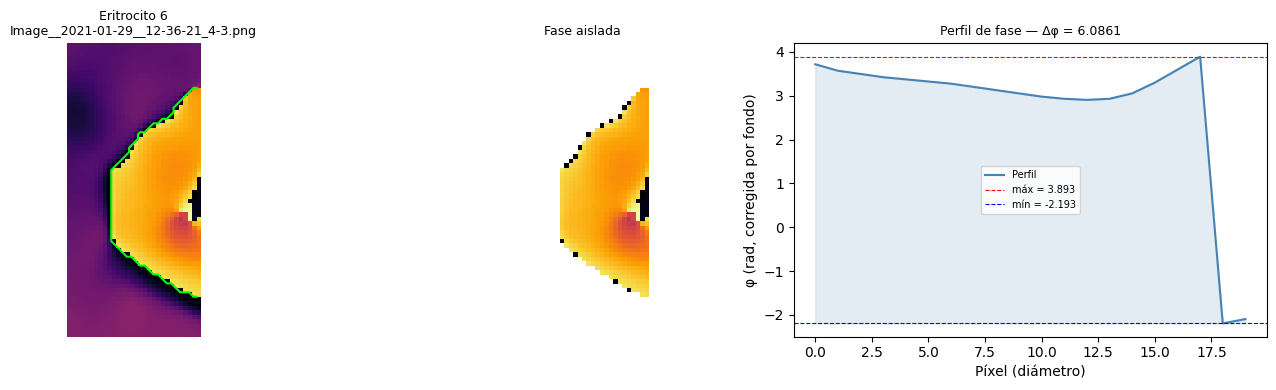

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__12-36-21_4-3.png


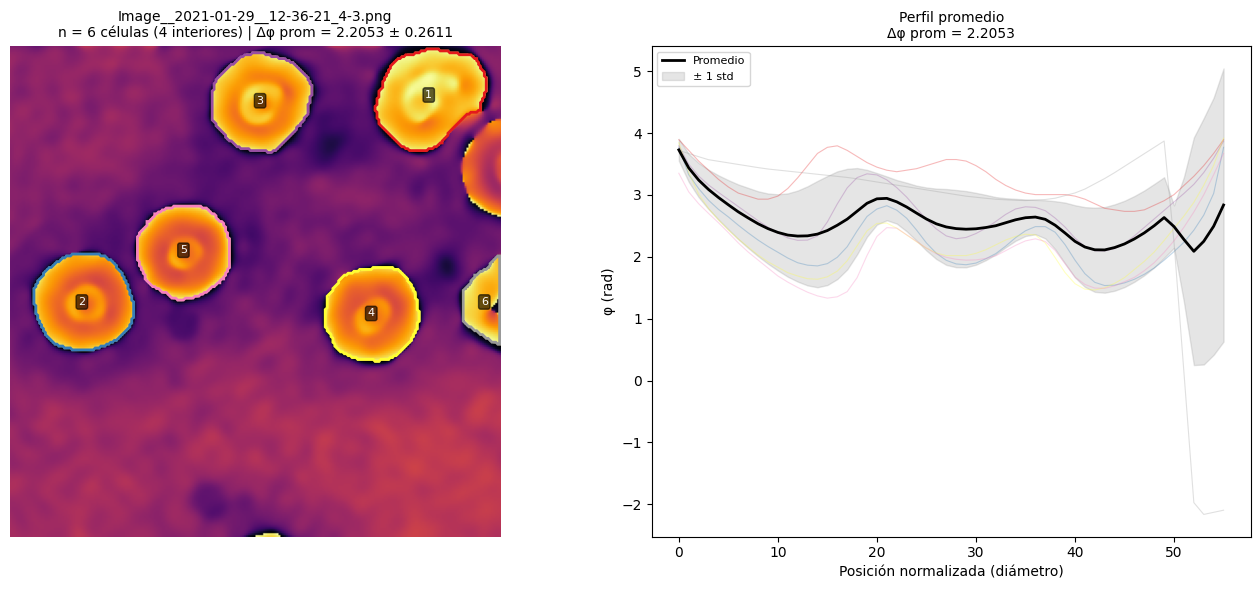


Imagen 2/8: Image__2021-01-29__13-12-01_4-1.png
    Rechazadas: area=6, forma=0, fusion=0, contraste=0, fondo=0
    Dedup (mismo eritrocito / barriguita): -3 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 13
  Eritrocitos válidos: 4


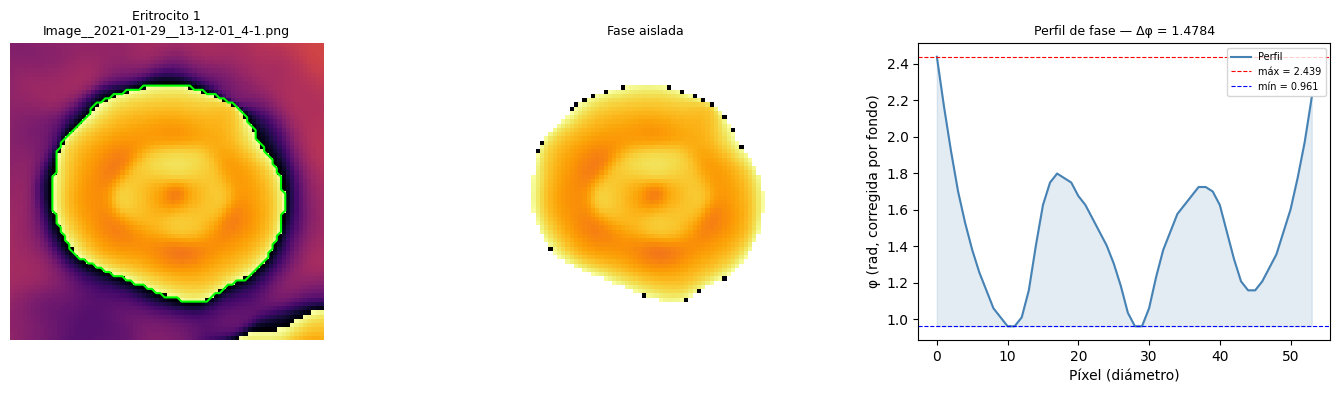

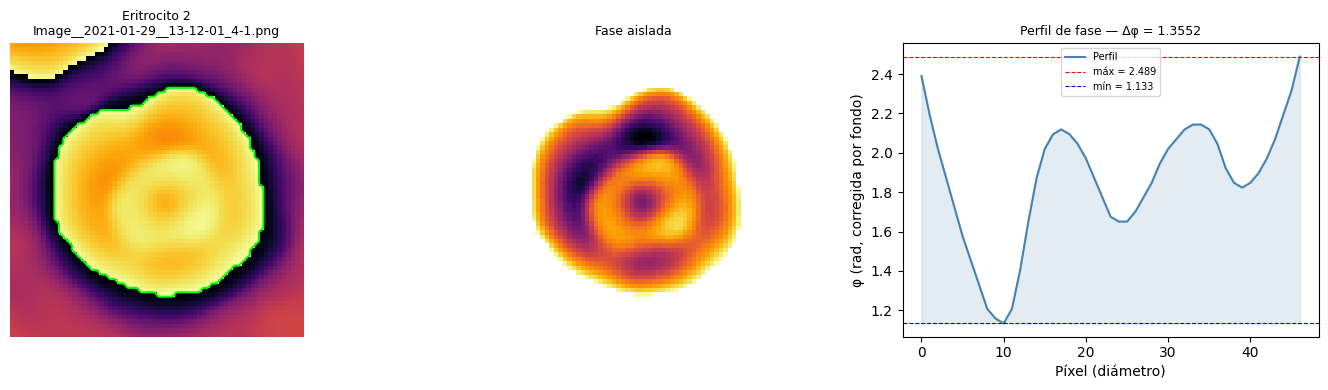

    Célula 3: 8 px de wrap reparados (+2π)


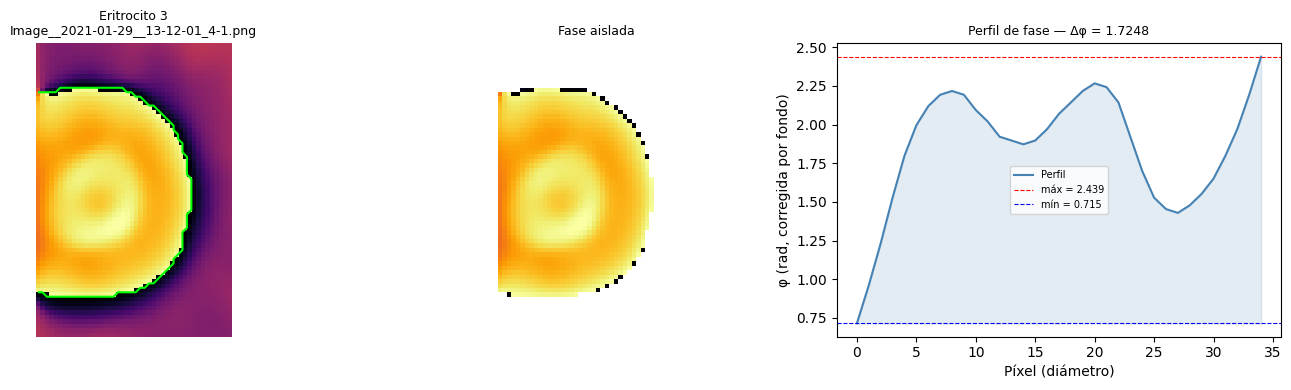

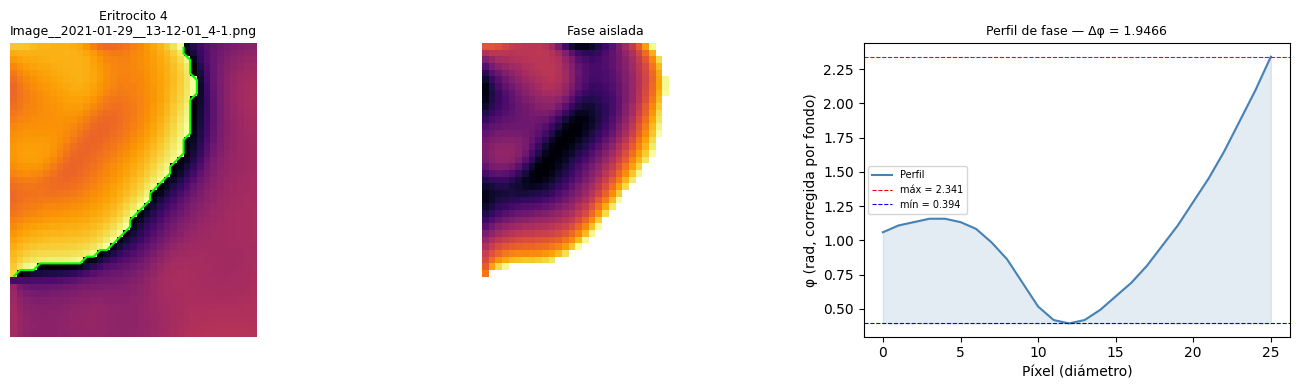

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-12-01_4-1.png


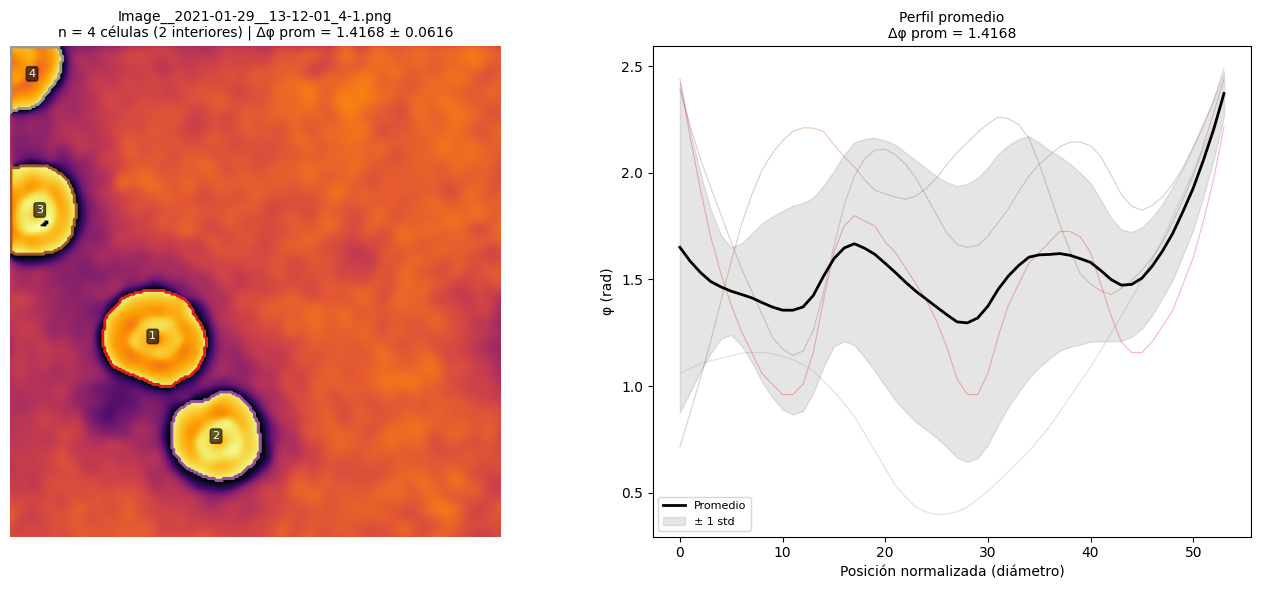


Imagen 3/8: Image__2021-01-29__13-26-59_3-8.png
    Rechazadas: area=4, forma=1, fusion=0, contraste=3, fondo=1
    Dedup (mismo eritrocito / barriguita): -5 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 21
  Eritrocitos válidos: 7


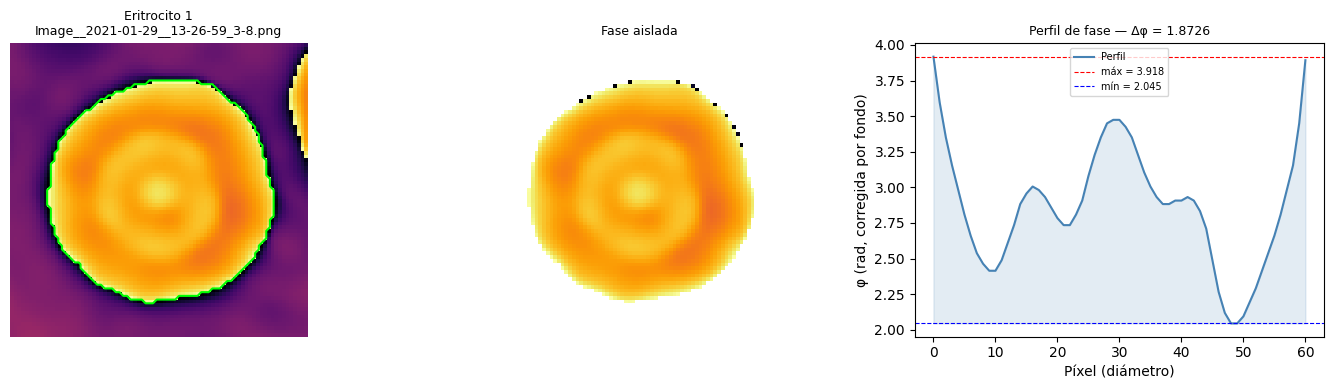

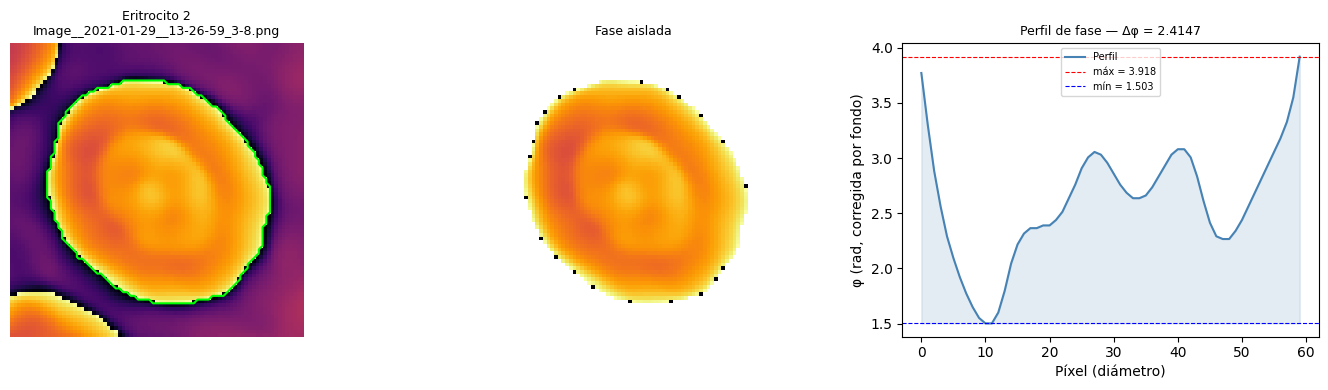

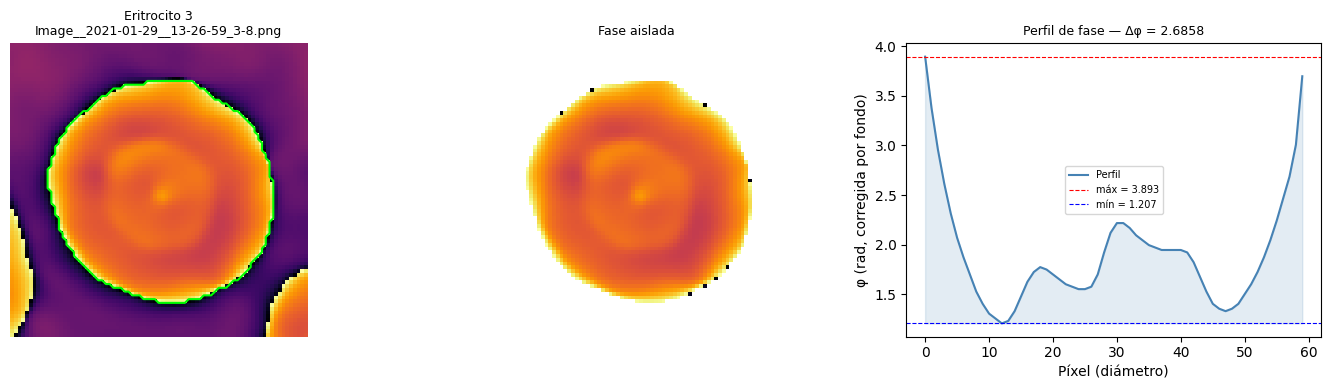

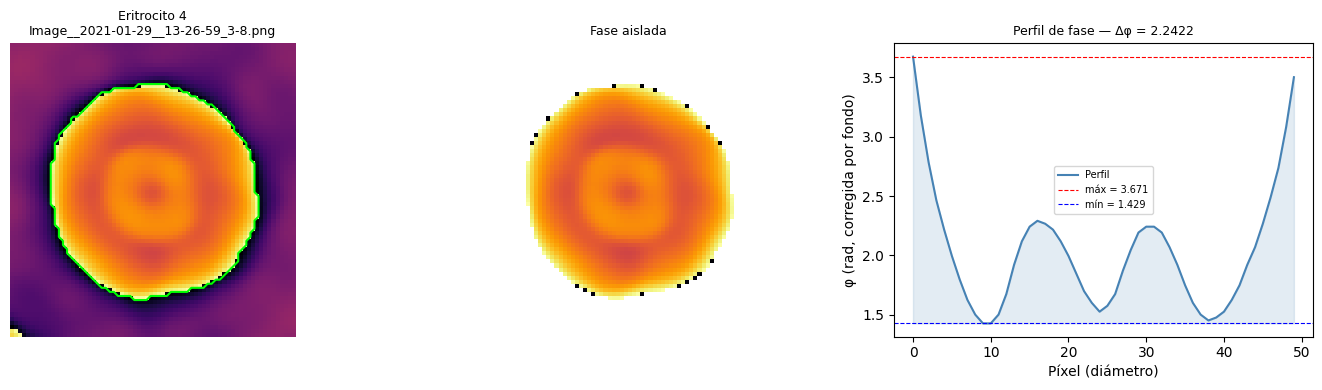

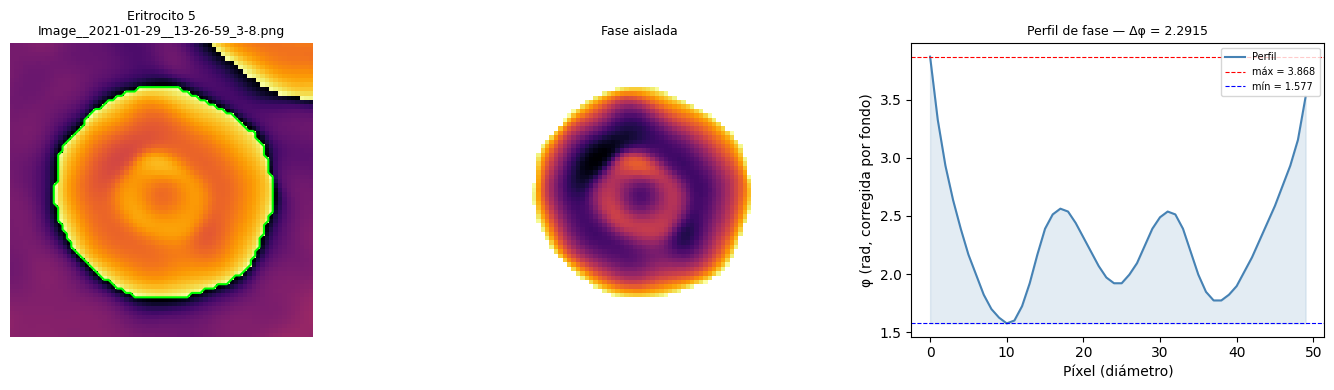

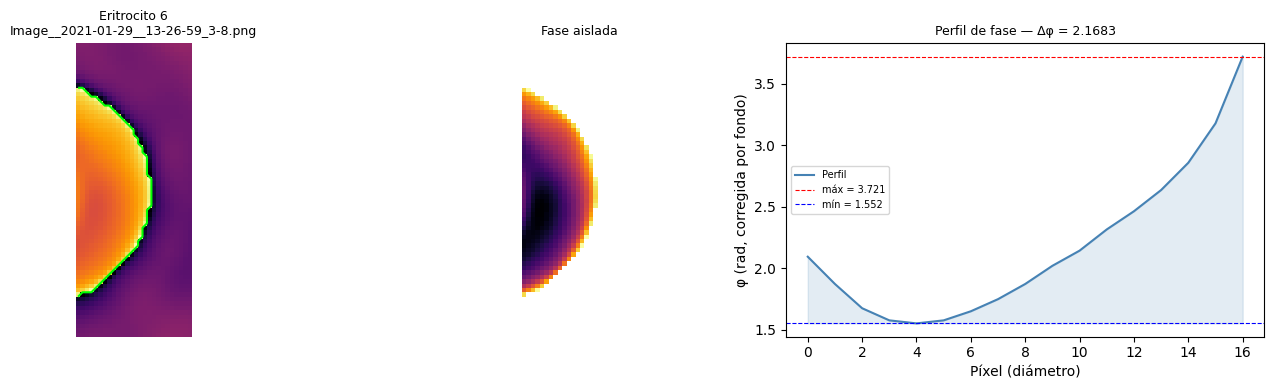

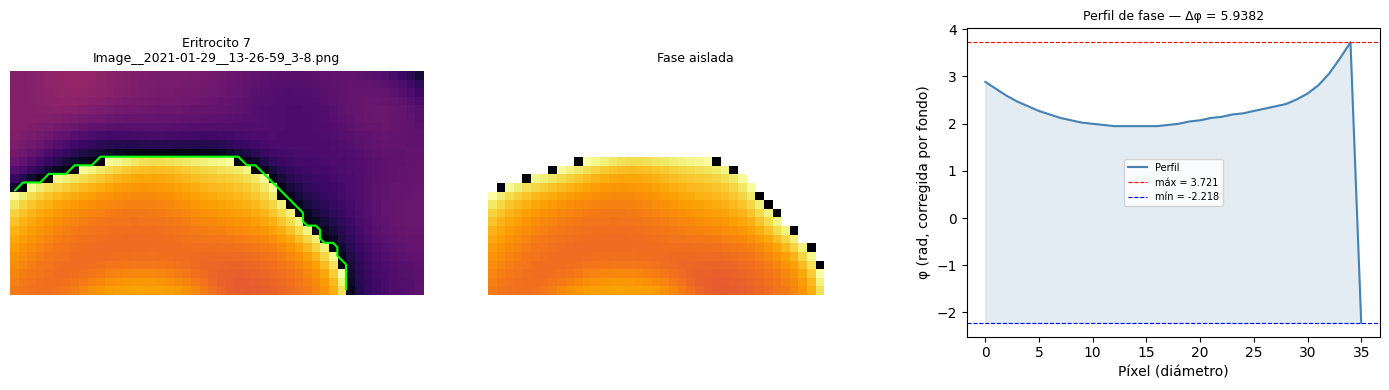

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-26-59_3-8.png


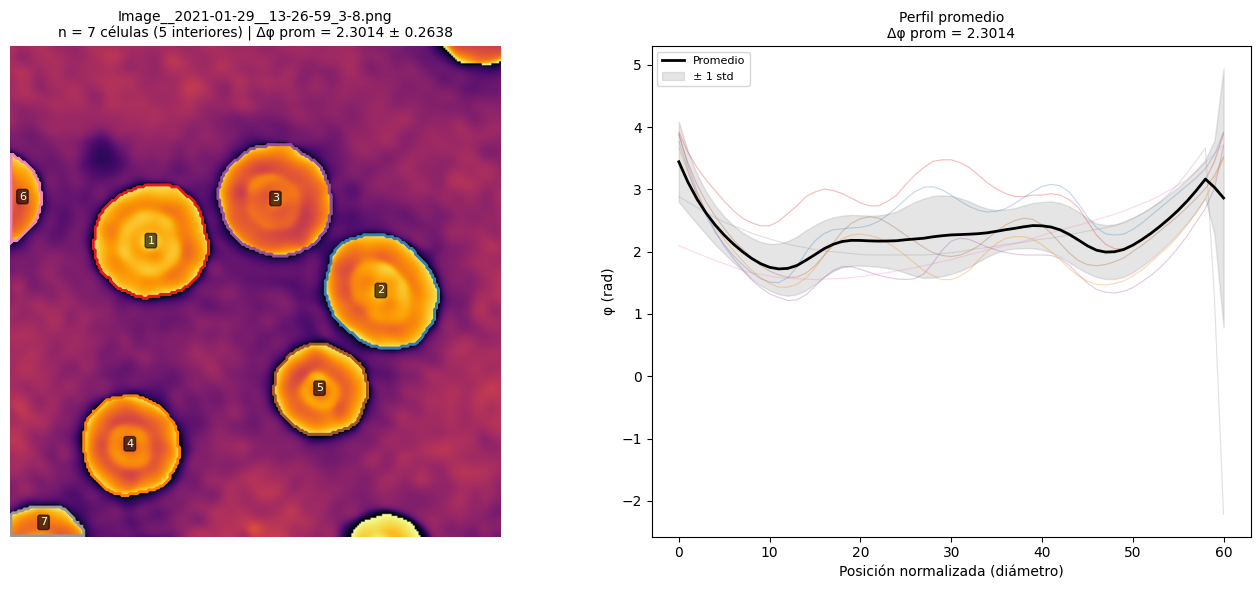


Imagen 4/8: Image__2021-01-29__13-12-01_4-11.png
    Rechazadas: area=11, forma=0, fusion=0, contraste=0, fondo=0
    Dedup (mismo eritrocito / barriguita): -1 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 14
  Eritrocitos válidos: 2


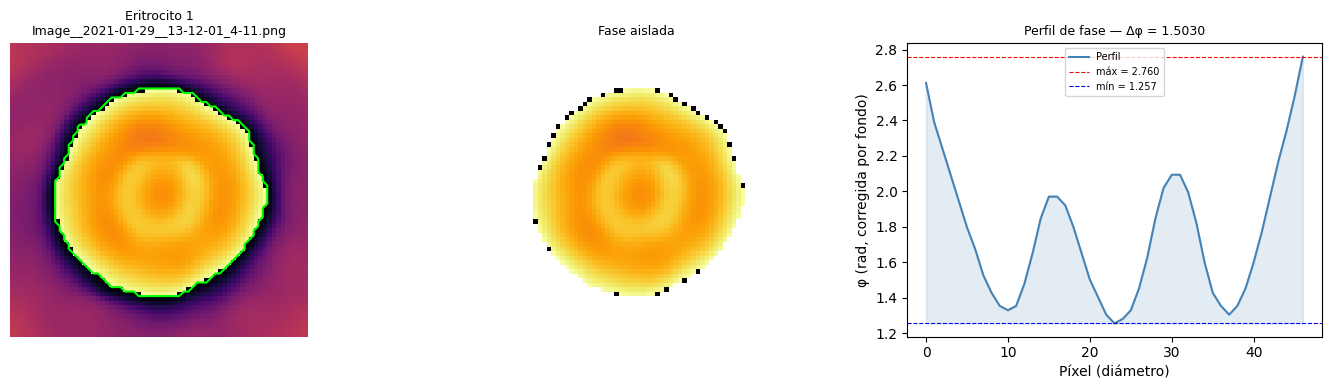

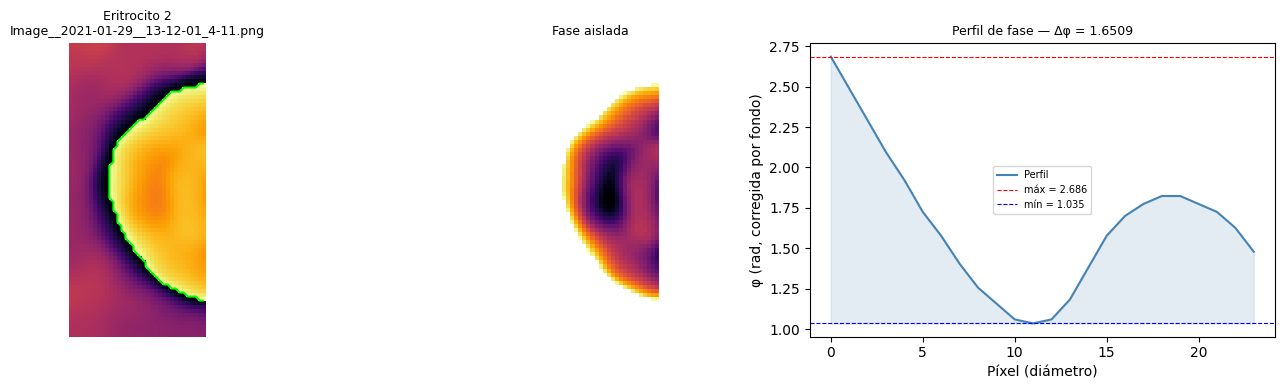

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-12-01_4-11.png


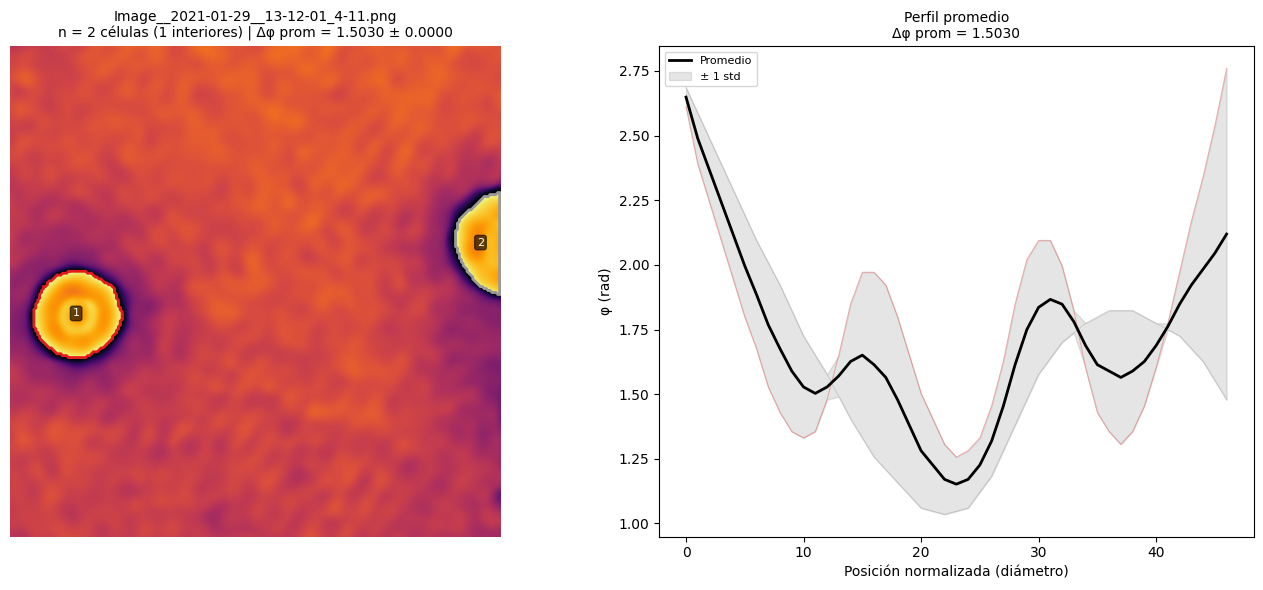


Imagen 5/8: Image__2021-01-29__13-12-45_2-1.png
    Rechazadas: area=10, forma=0, fusion=0, contraste=1, fondo=0
    Dedup (mismo eritrocito / barriguita): -3 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 18
  Eritrocitos válidos: 4


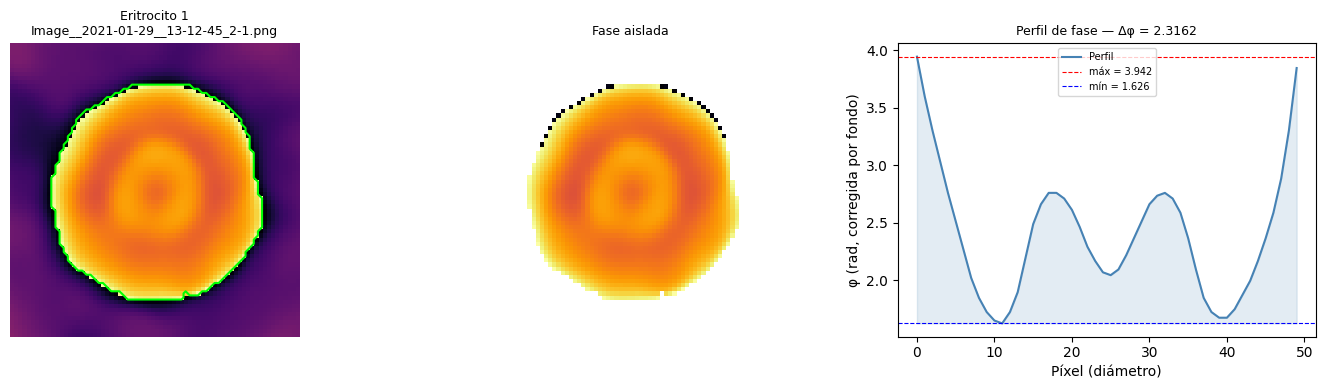

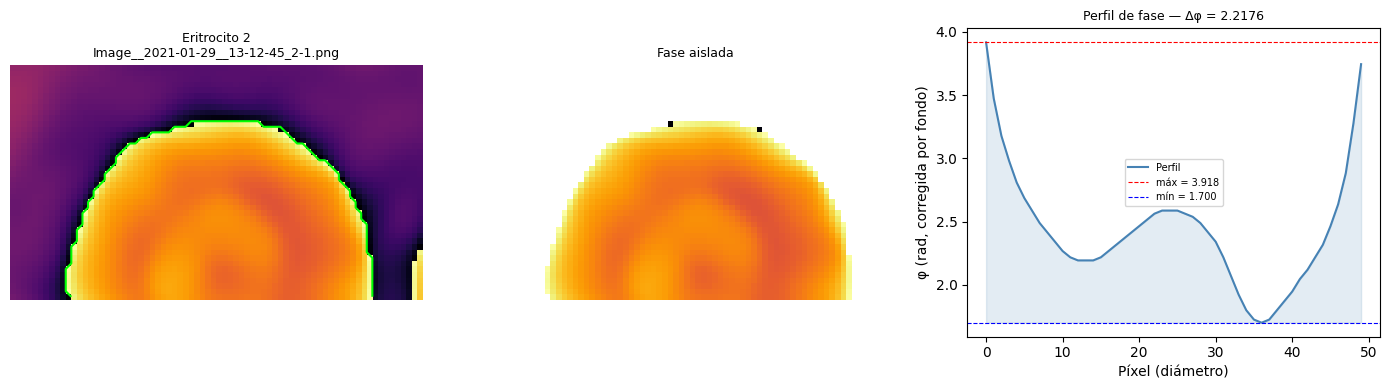

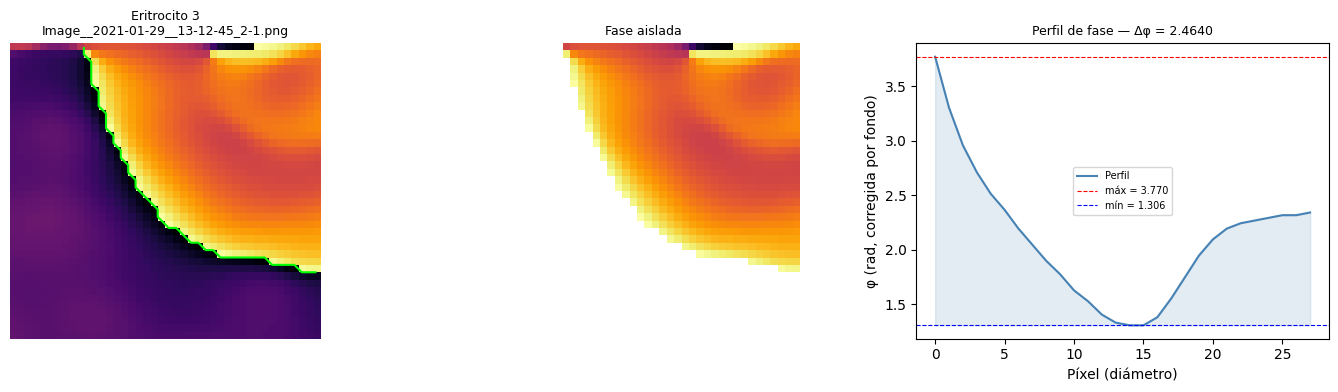

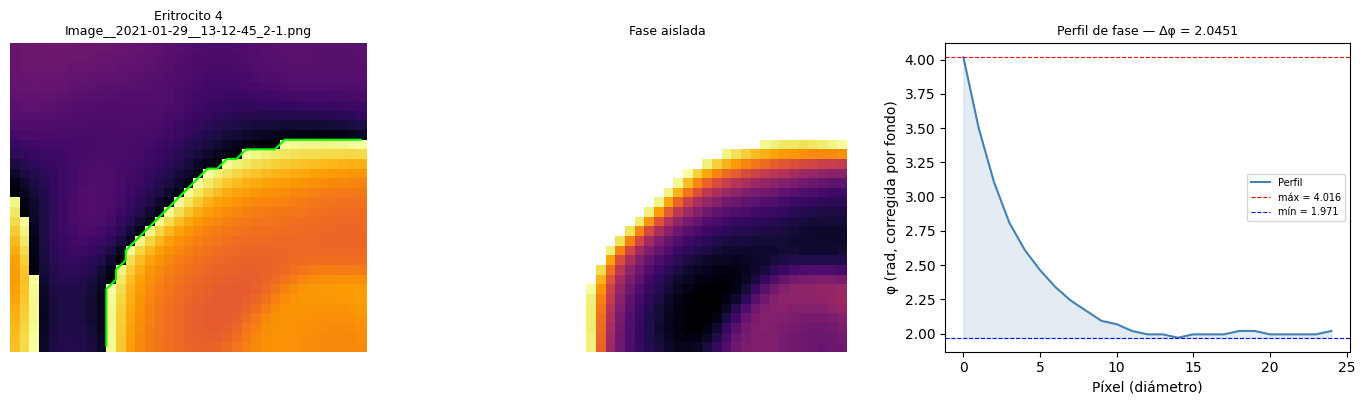

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-12-45_2-1.png


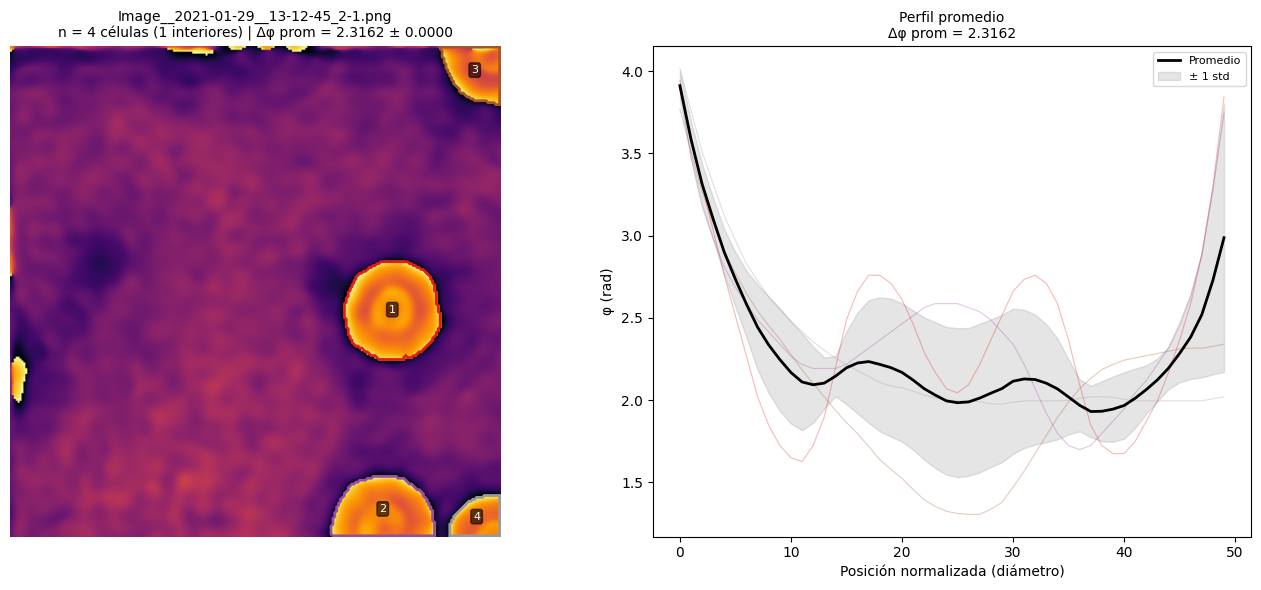


Imagen 6/8: Image__2021-01-28__16-04-31_3-3.png
    Rechazadas: area=2, forma=0, fusion=0, contraste=0, fondo=0
    Dedup (mismo eritrocito / barriguita): -3 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 9
  Eritrocitos válidos: 4


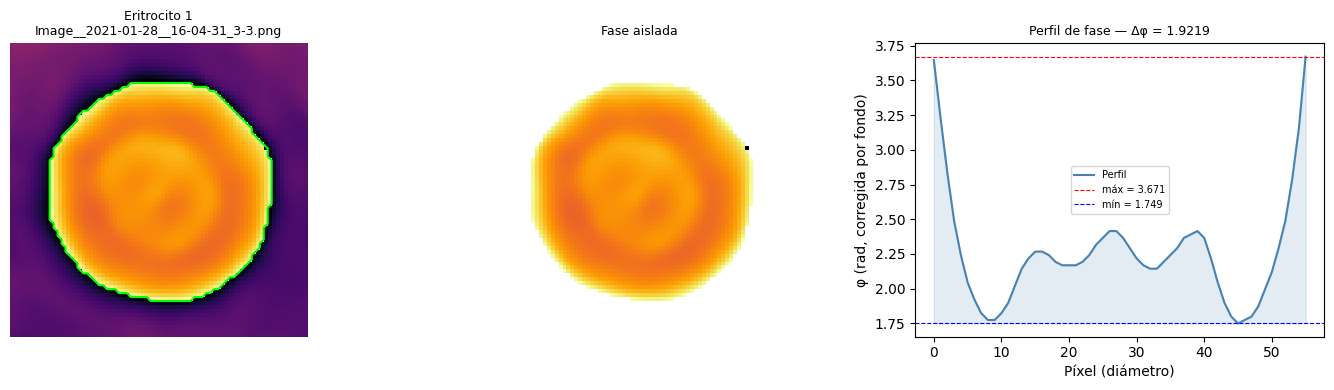

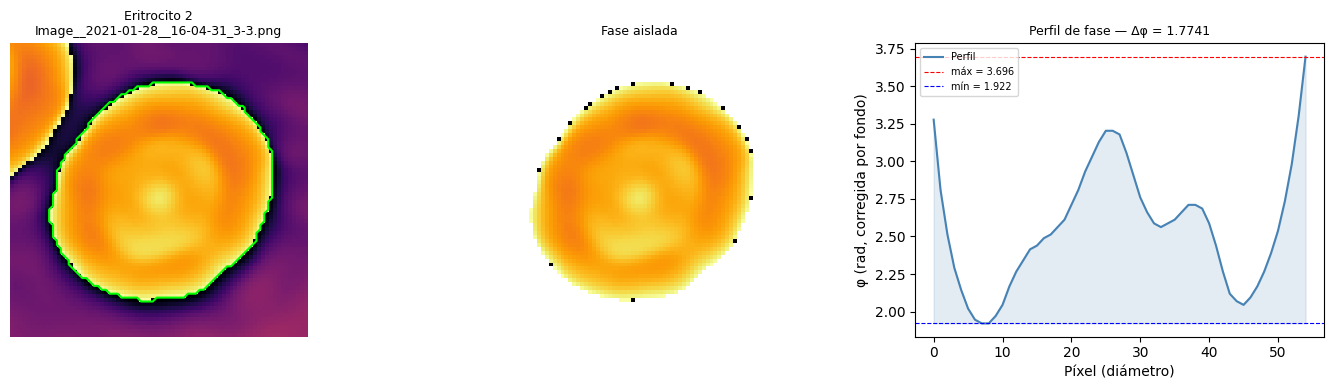

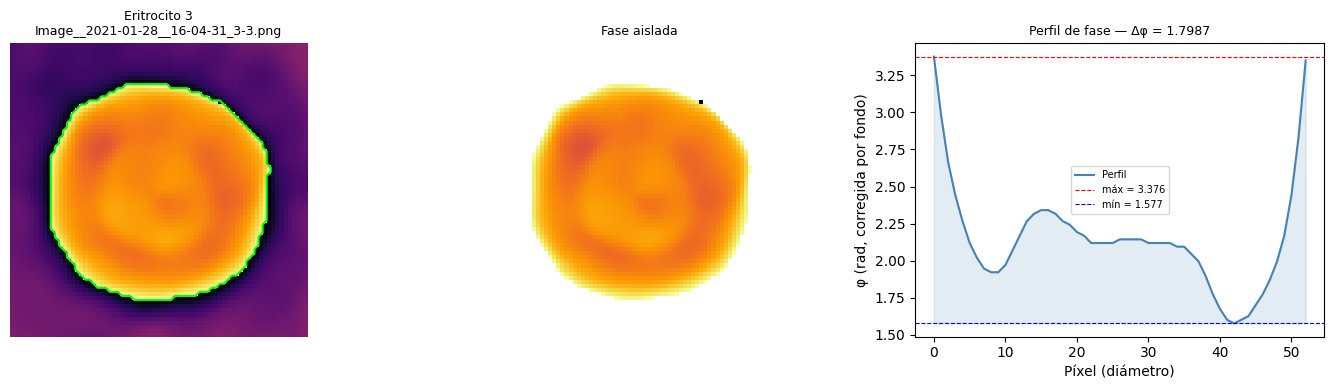

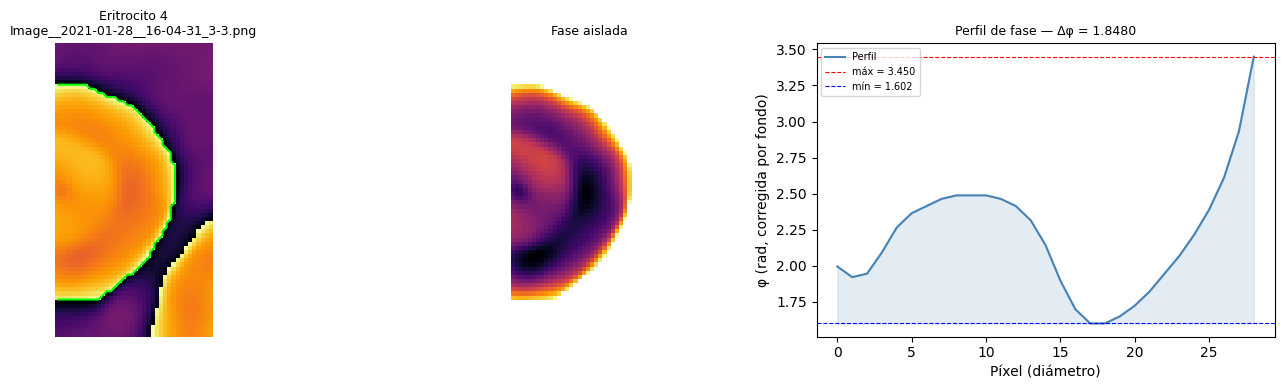

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-28__16-04-31_3-3.png


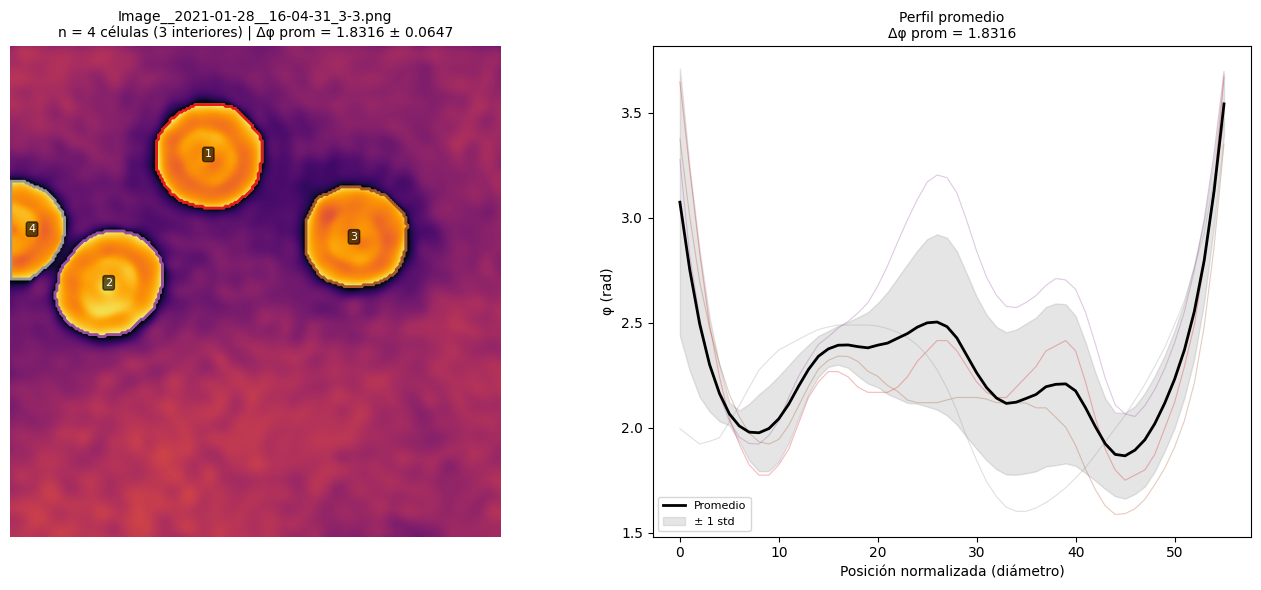


Imagen 7/8: Image__2021-01-29__13-15-19_3-6.png
    Rechazadas: area=12, forma=0, fusion=0, contraste=0, fondo=0
    Dedup (mismo eritrocito / barriguita): -9 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 31
  Eritrocitos válidos: 10


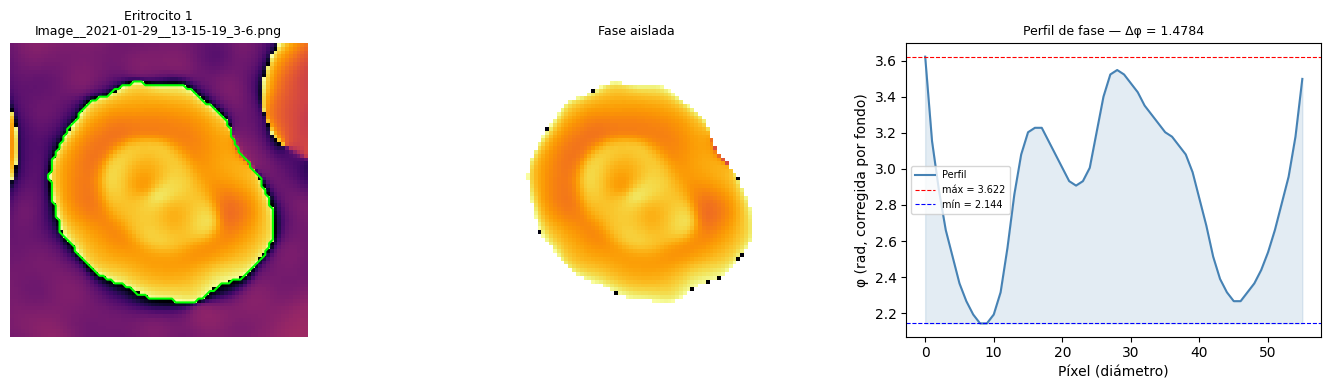

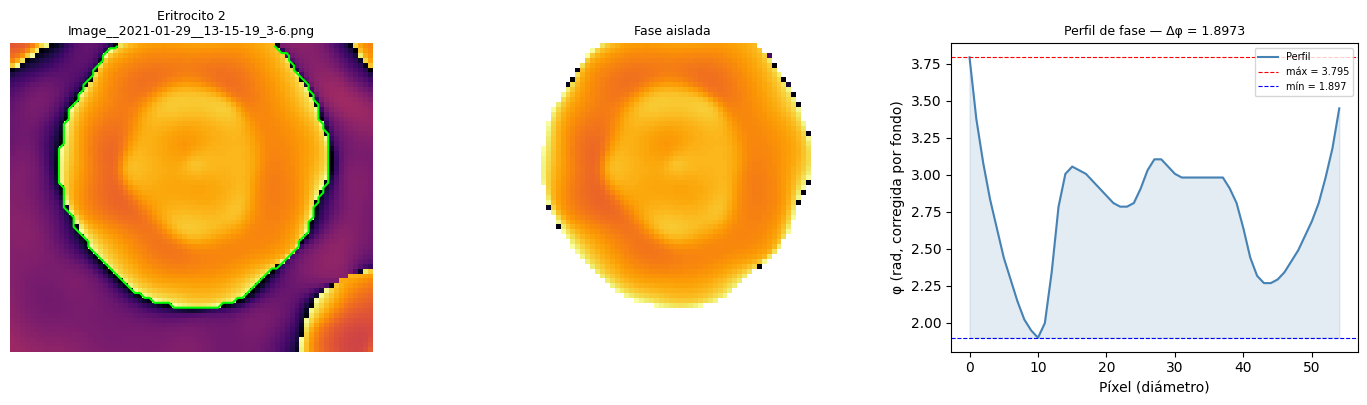

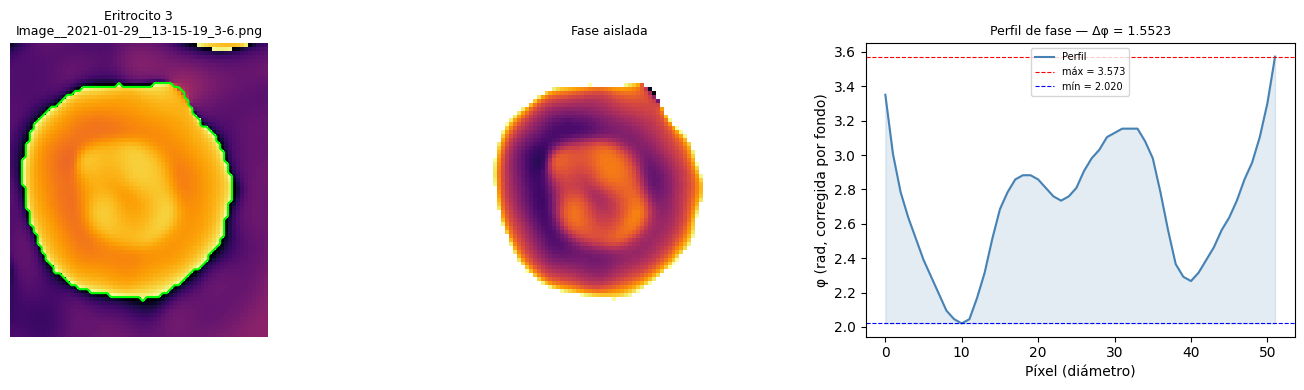

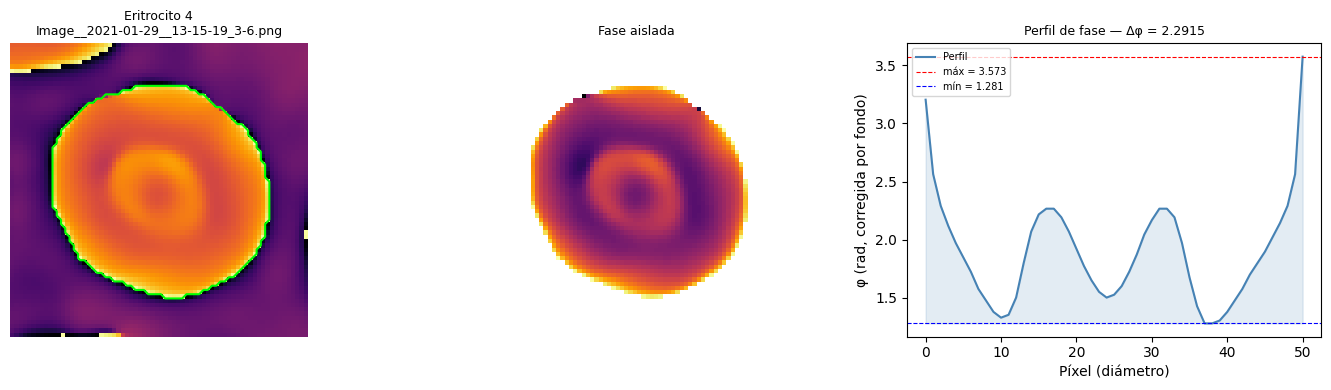

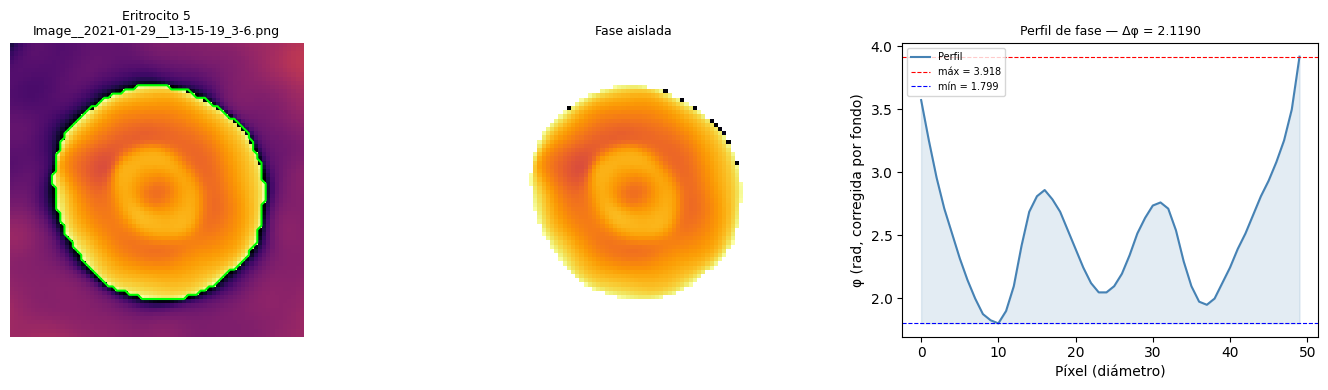

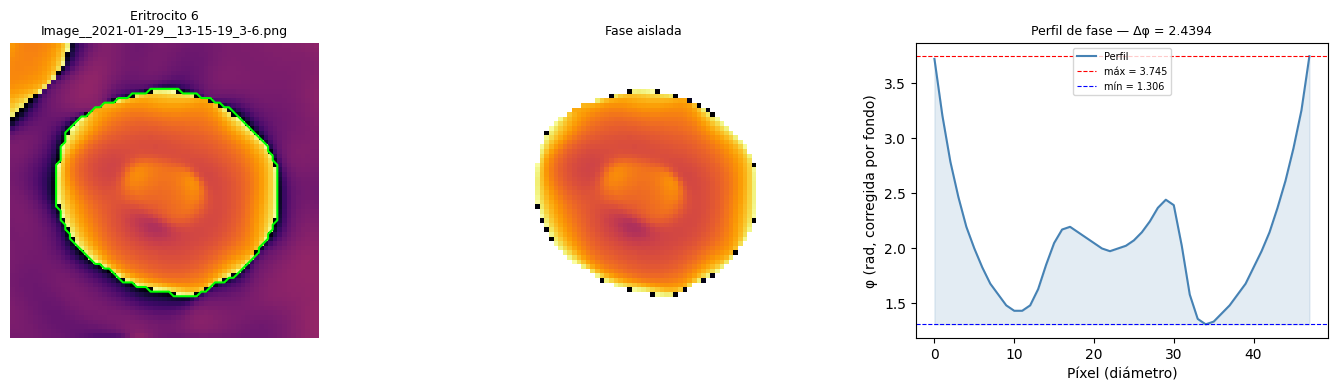

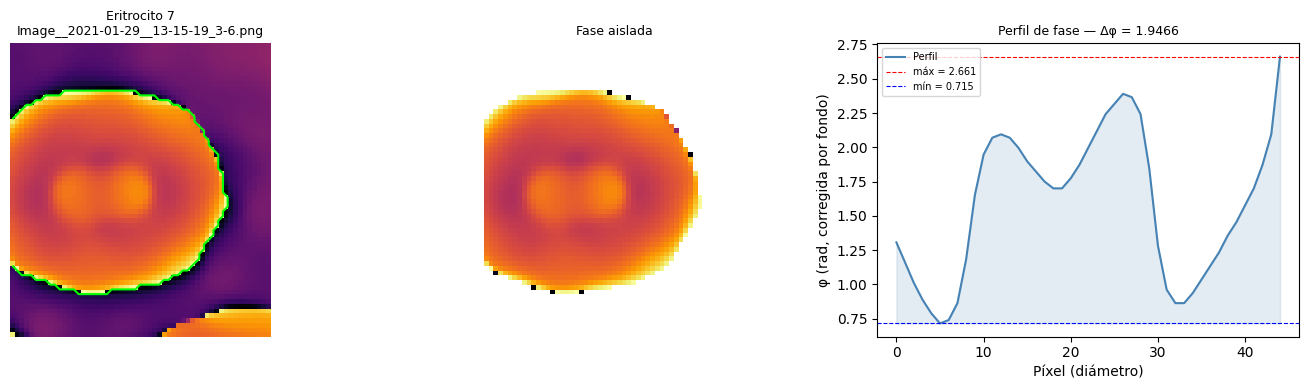

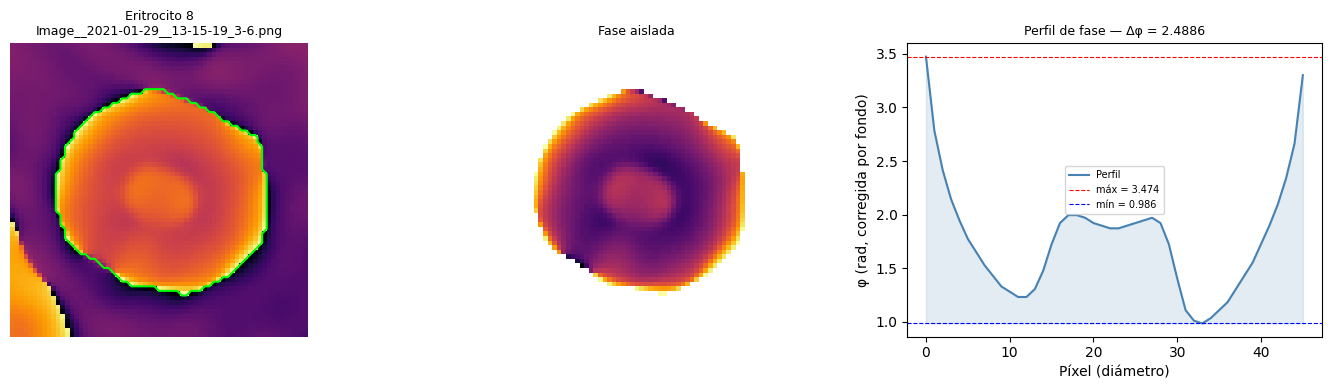

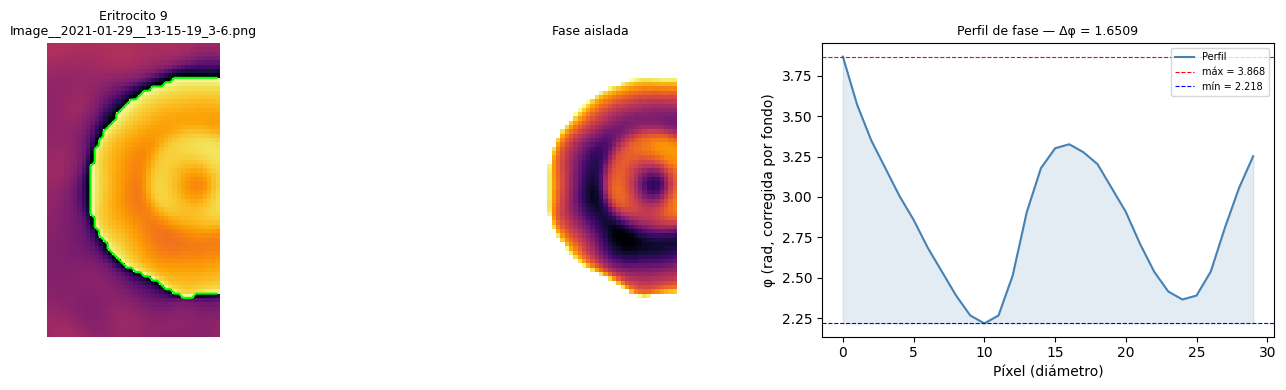

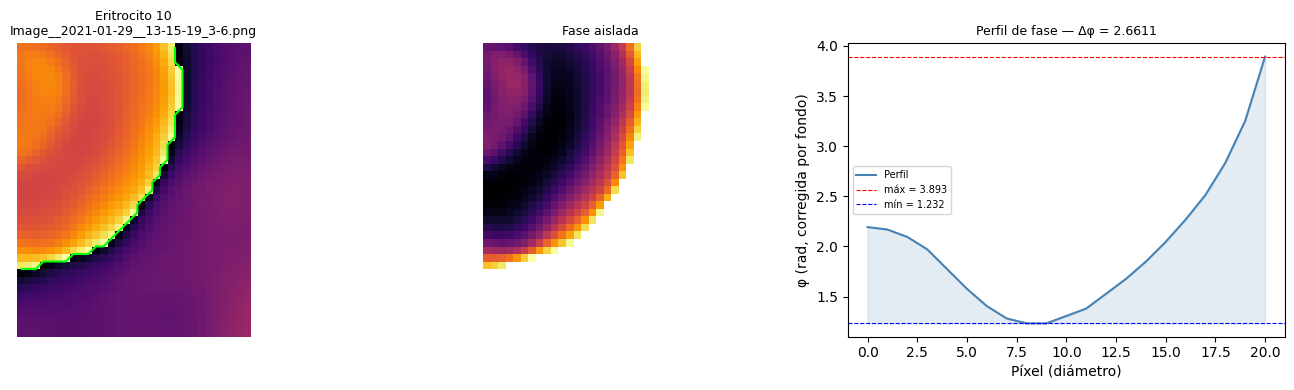

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__13-15-19_3-6.png


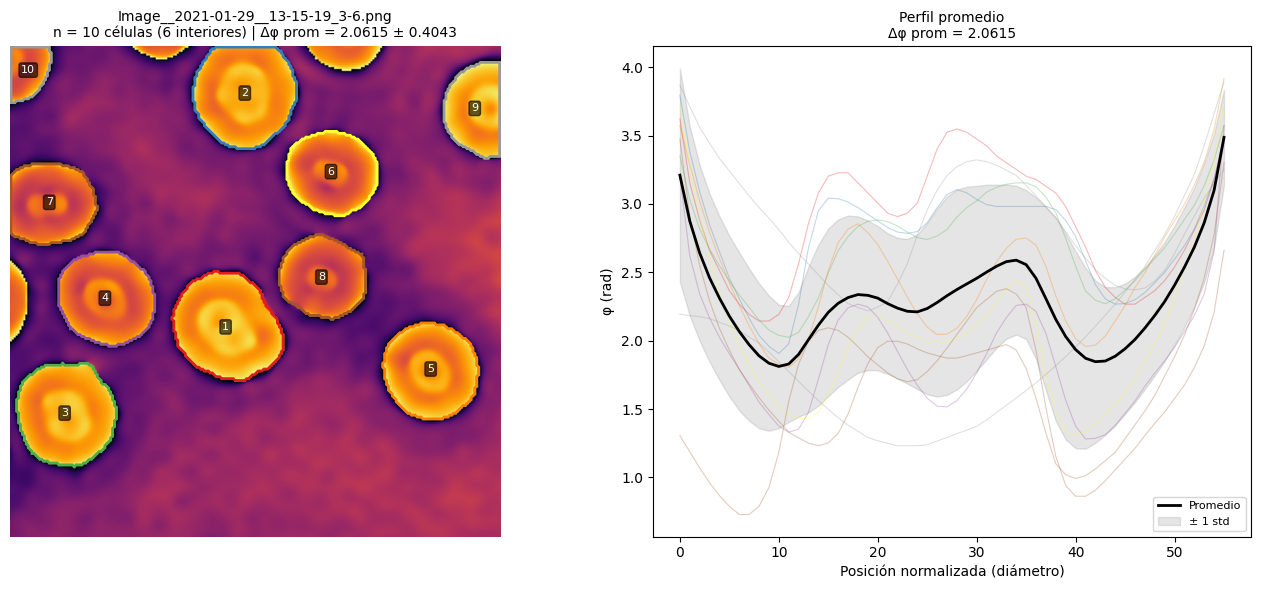


Imagen 8/8: Image__2021-01-29__12-53-41_1-6.png
    Rechazadas: area=8, forma=0, fusion=0, contraste=0, fondo=0
    Dedup (mismo eritrocito / barriguita): -2 | recuperadas por Otsu: +0
  Máscaras SAM crudas: 18
  Eritrocitos válidos: 8


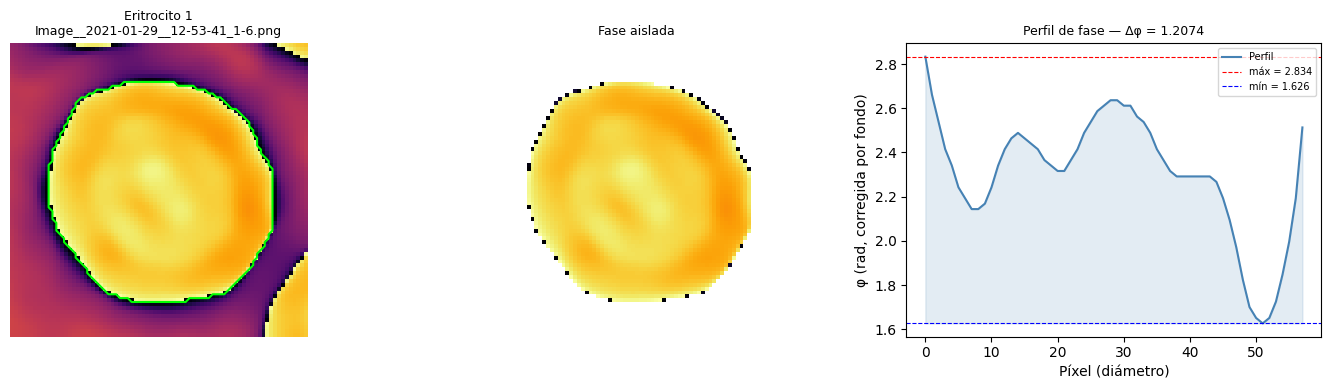

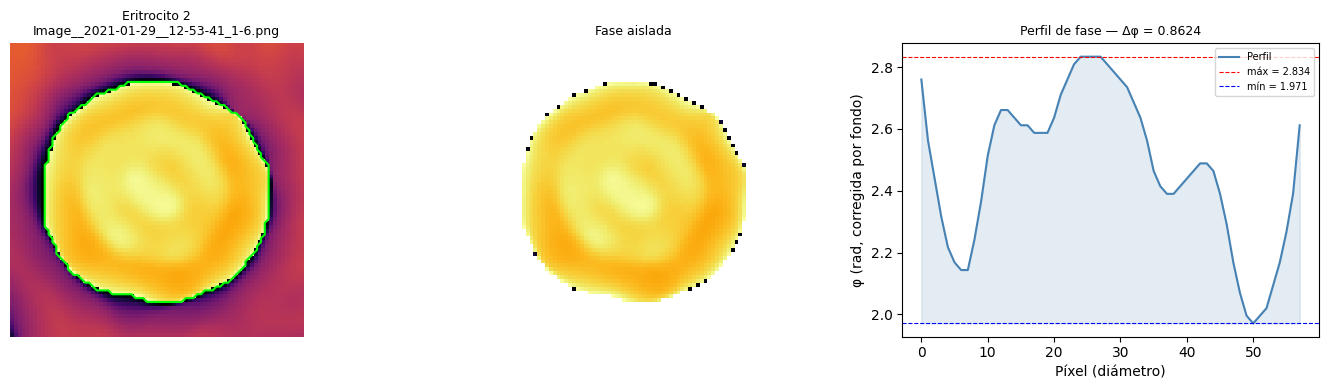

    Célula 3: 88 px de wrap reparados (+2π)


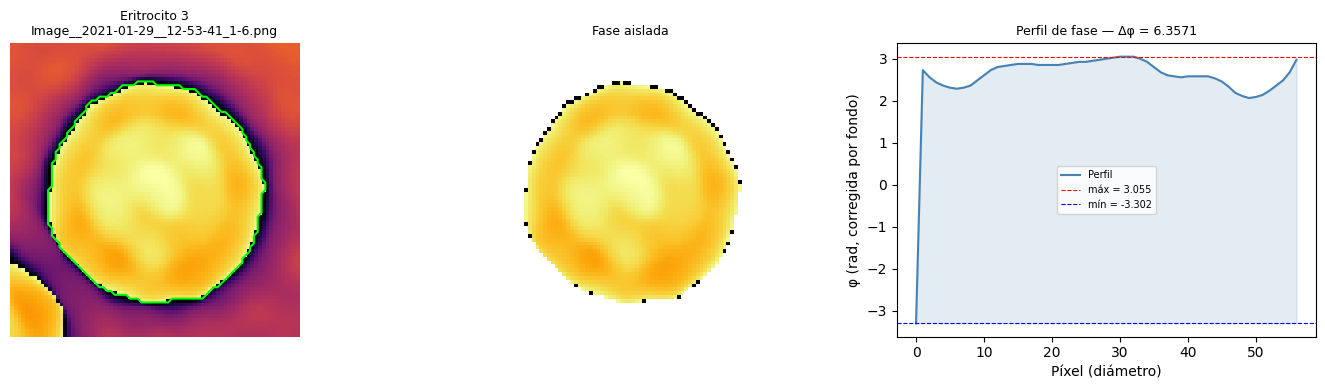

    Célula 4: 12 px de wrap reparados (+2π)


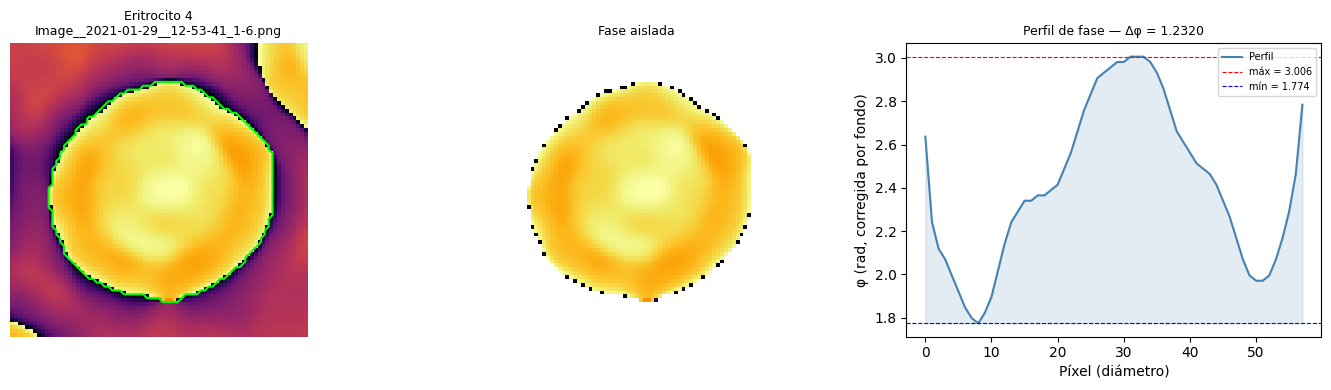

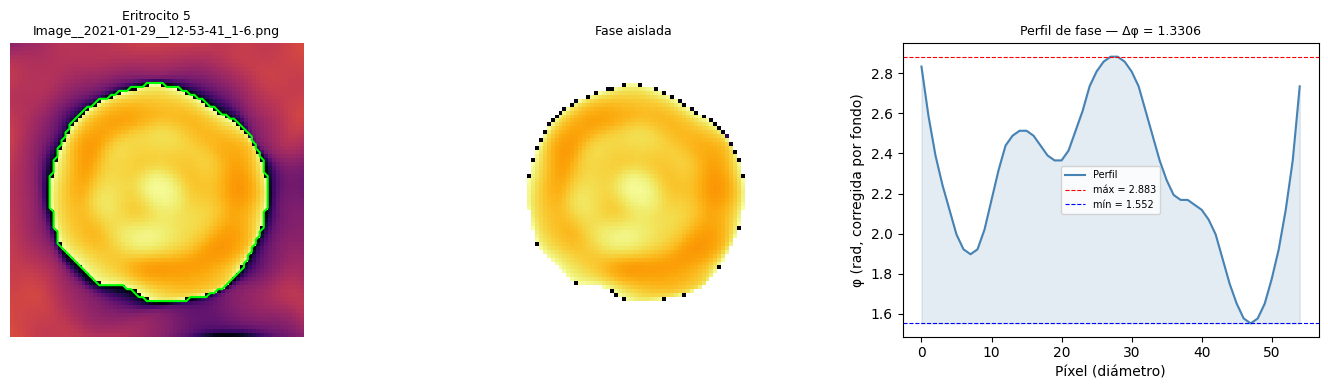

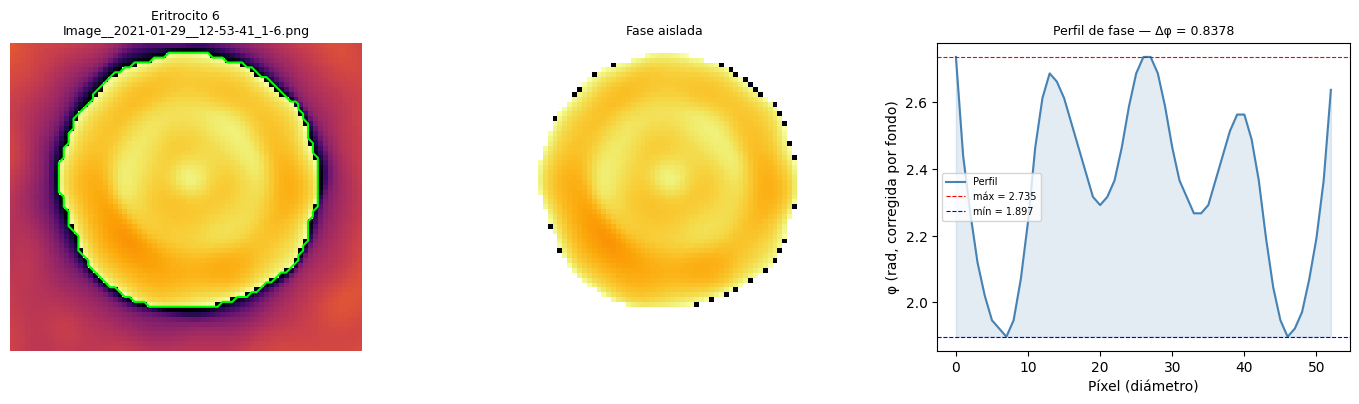

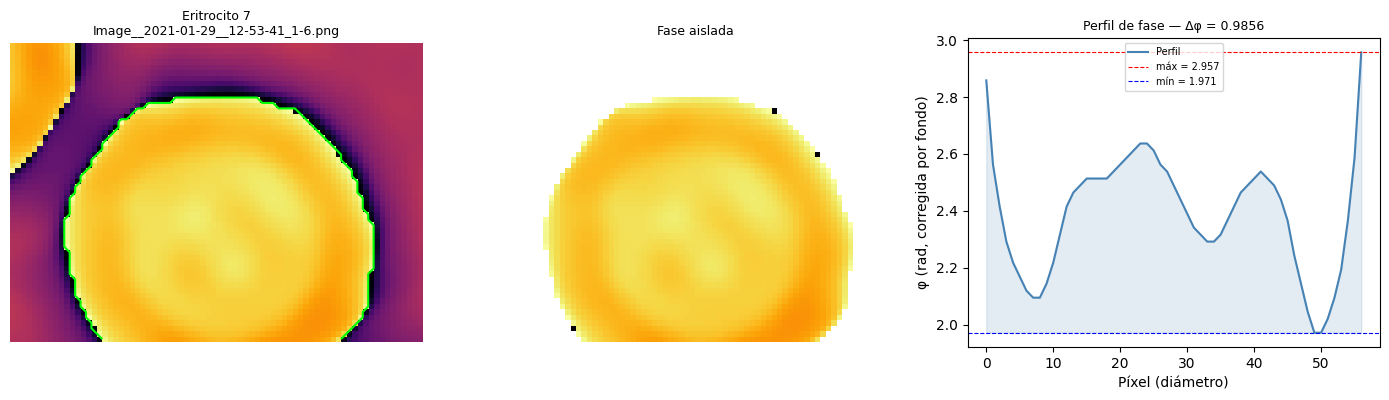

    Célula 8: 183 px de wrap reparados (+2π)


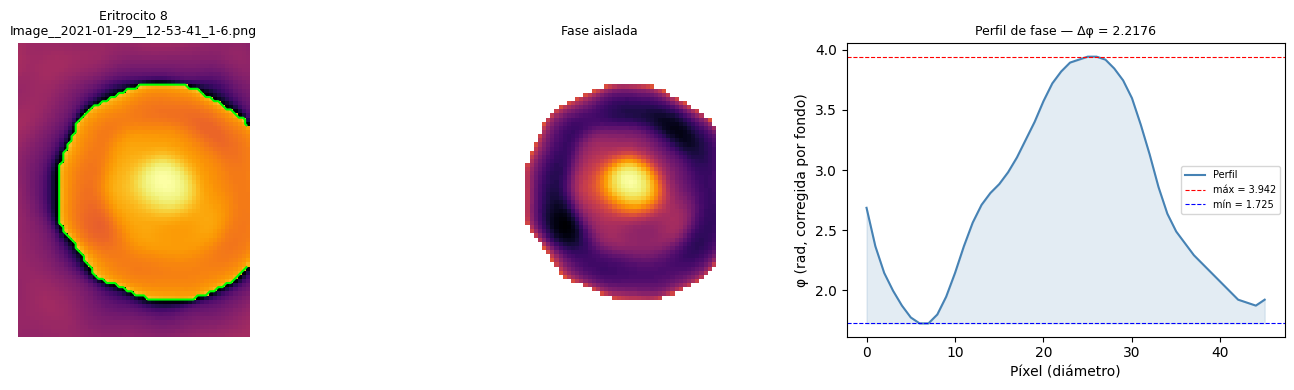

  Guardado: /content/data/processed/heuristica_validacion/annotated_Image__2021-01-29__12-53-41_1-6.png


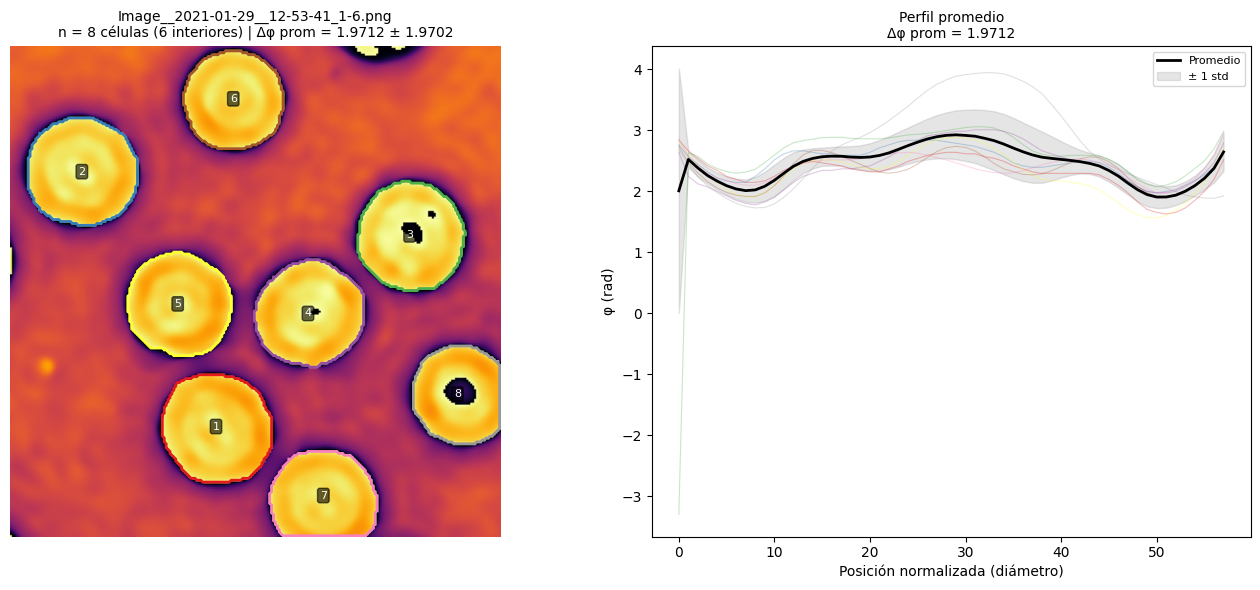


Procesamiento completado: 8 imágenes.


In [30]:
# Directorio para guardar imágenes anotadas
SAVE_DIR = Path('/content/data/processed/heuristica_validacion')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Acumuladores de resultados
all_results = []         # una fila por imagen
all_cell_results = []    # una fila por célula

for img_idx, (_, row) in enumerate(sample_df.iterrows()):
    img_path = IMG_ROOT / row['file']
    img_name = Path(row['file']).name

    print(f'\n{"="*70}')
    print(f'Imagen {img_idx + 1}/{len(sample_df)}: {img_name}')
    print(f'{"="*70}')

    # Cargar imagen
    gray = np.array(Image.open(img_path).convert('L'))
    phi = to_phase(gray)   # [-1, 1]

    # SAM requiere entrada RGB (H, W, 3) en uint8
    rgb_for_sam = np.stack([gray, gray, gray], axis=-1)

    #  Generar y filtrar máscaras
    raw_masks = mask_generator.generate(rgb_for_sam)
    cell_masks = filter_cell_masks(raw_masks, phase_img=phi)

    print(f'  Máscaras SAM crudas: {len(raw_masks)}')
    print(f'  Eritrocitos válidos: {len(cell_masks)}')

    if len(cell_masks) == 0:
        print('  Sin eritrocitos detectados en esta imagen. Se registra con n_cells=0.')
        all_results.append({
            'img_name': img_name,
            'n_cells': 0,
            'delta_phi_mean': np.nan,
            'delta_phi_std': np.nan,
            'delta_phi_median': np.nan,
            'n_cells_interior': 0,
            'delta_phi_min': np.nan,
            'delta_phi_max': np.nan,
        })
        continue

    #  Máscara global (unión de todas las células) para el fondo
    all_cells_mask = np.zeros_like(gray, dtype=bool)
    for m in cell_masks:
        all_cells_mask |= m['segmentation']

    # Perfil y delta por célula
    profiles = []
    deltas = []
    centroids = []
    border_flags = []

    for cell_id, m in enumerate(cell_masks, 1):
        seg = m['segmentation']

        # Corrige huecos negros por wrap de fase (+2π) solo dentro de esta célula
        phi_c, n_fix = repair_wrapped_spots(phi, seg)
        if n_fix:
            print(f'    Célula {cell_id}: {n_fix} px de wrap reparados (+2π)')

        profile, delta_phi, centroid, bg_val = extract_phase_profile_bg_global(
            phi_c, seg, all_cells_mask
        )

        profiles.append(profile)
        deltas.append(delta_phi)
        centroids.append(centroid)
        border_flags.append(touches_border(seg))

        all_cell_results.append({
            'img_name': img_name,
            'cell_id': cell_id,
            'delta_phi': delta_phi,
            'profile_len': len(profile),
            'en_borde': touches_border(seg),
            'px_wrap_reparados': n_fix,
            'area_px': int(seg.sum()),
            'circularity': circularity(seg),
            'centroid_y': centroid[0],
            'centroid_x': centroid[1],
            'bg_value': bg_val,
        })

        # Visualización individual por célula
        plot_cell_panel(phi_c, seg, profile, delta_phi, centroid, cell_id, img_name)

    # Imagen anotada con promedios
    mean_d, std_d = annotate_image(
        phi, cell_masks, deltas, profiles, centroids,
        img_name, save_dir=SAVE_DIR, is_border=border_flags
    )
    d_int = [d for d, b in zip(deltas, border_flags) if not b] or deltas

    all_results.append({
        'img_name': img_name,
        'n_cells': len(cell_masks),
        'delta_phi_mean': mean_d,
        'delta_phi_std': std_d,
        'delta_phi_median': float(np.median(d_int)),
        'n_cells_interior': sum(not b for b in border_flags),
        'delta_phi_min': min(d_int),
        'delta_phi_max': max(d_int),
    })

print(f'\n{"="*70}')
print(f'Procesamiento completado: {len(sample_df)} imágenes.')
print(f'{"="*70}')

## 5. Resumen

In [31]:
#  Tabla resumen por imagen
df_img = pd.DataFrame(all_results)
print('Resultados por imagen:')
print(df_img.to_string(index=False))

valid_imgs = df_img.dropna(subset=['delta_phi_mean'])
print(f'\n──────────────────────────────────────────────')
print(f'Imágenes procesadas con células: {len(valid_imgs)} / {len(df_img)}')
print(f'Δφ promedio general: {valid_imgs["delta_phi_mean"].mean():.4f}')
print(f'Δφ std general:      {valid_imgs["delta_phi_mean"].std():.4f}')
print(f'Δφ mediana general:  {valid_imgs["delta_phi_median"].median():.4f}  (rad, solo células interiores)')
print(f'Células totales:     {valid_imgs["n_cells"].sum()}')
print(f'──────────────────────────────────────────────')

Resultados por imagen:
                            img_name  n_cells  delta_phi_mean  delta_phi_std  delta_phi_median  n_cells_interior  delta_phi_min  delta_phi_max
 Image__2021-01-29__12-36-21_4-3.png        6        2.205275       0.261056          2.291515                 4       1.774076       2.463994
 Image__2021-01-29__13-12-01_4-1.png        4        1.416797       0.061600          1.416797                 2       1.355197       1.478397
 Image__2021-01-29__13-26-59_3-8.png        7        2.301371       0.263820          2.291515                 5       1.872636       2.685754
Image__2021-01-29__13-12-01_4-11.png        2        1.503036       0.000000          1.503036                 1       1.503036       1.503036
 Image__2021-01-29__13-12-45_2-1.png        4        2.316155       0.000000          2.316155                 1       2.316155       2.316155
 Image__2021-01-28__16-04-31_3-3.png        4        1.831569       0.064672          1.798716                 3       

In [32]:
# Tabla resumen por célula
df_cell = pd.DataFrame(all_cell_results)
df_int = df_cell[~df_cell['en_borde']].copy()   # solo células completas (sin tocar el borde)
print(f'Total de células segmentadas: {len(df_cell)} ({len(df_int)} interiores, usadas en las estadísticas)')
print(f'\nEstadísticas del delta de fase por célula:')
print(df_int['delta_phi'].describe().to_string())
df_cell.head(10)

Total de células segmentadas: 45 (28 interiores, usadas en las estadísticas)

Estadísticas del delta de fase por célula:
count    28.000000
mean      2.023995
std       0.993657
min       0.837758
25%       1.478397
50%       1.897276
75%       2.322315
max       6.357105


,img_name,cell_id,delta_phi,profile_len,en_borde,px_wrap_reparados,area_px,circularity,centroid_y,centroid_x,bg_value
0,Image__2021-01-29__12-36-21_4-3.png,1,1.158077,56,True,0,2299,0.824496,25,218,-0.825438
1,Image__2021-01-29__12-36-21_4-3.png,2,2.242235,53,False,0,2131,0.894173,133,37,-0.825438
2,Image__2021-01-29__12-36-21_4-3.png,3,1.774076,52,False,0,2119,0.890662,28,130,-0.825438
3,Image__2021-01-29__12-36-21_4-3.png,4,2.463994,50,False,0,1981,0.887940,139,188,-0.825438
4,Image__2021-01-29__12-36-21_4-3.png,5,2.340795,49,False,0,1937,0.869808,106,90,-0.825438
5,Image__2021-01-29__12-36-21_4-3.png,6,6.086066,20,True,10,670,0.595166,133,247,-0.825438
6,Image__2021-01-29__13-12-01_4-1.png,1,1.478397,54,False,0,2137,0.867253,151,74,0.603679
7,Image__2021-01-29__13-12-01_4-1.png,2,1.355197,47,False,0,1711,0.876342,203,107,0.603679
8,Image__2021-01-29__13-12-01_4-1.png,3,1.724796,35,True,8,1448,0.820483,85,15,0.603679
9,Image__2021-01-29__13-12-01_4-1.png,4,1.946555,26,True,0,769,0.732483,14,11,0.603679


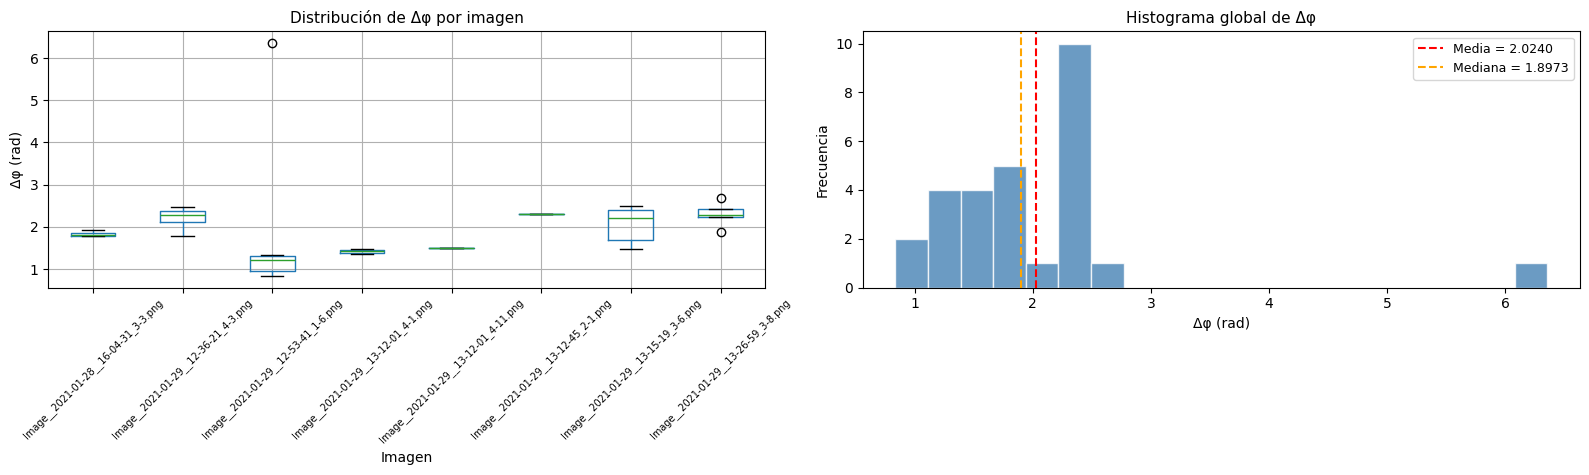

In [33]:
# Boxplot: distribución de Δφ por imagen
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Boxplot por imagen
ax = axes[0]
if len(df_int) > 0:
    df_int.boxplot(column='delta_phi', by='img_name', ax=ax, rot=45)
    ax.set_title('Distribución de Δφ por imagen', fontsize=11)
    ax.set_xlabel('Imagen')
    ax.set_ylabel('Δφ (rad)')
    plt.sca(ax)
    plt.xticks(fontsize=7)
    fig.suptitle('')  # quitar título automático de pandas

# Histograma global de Δφ
ax = axes[1]
if len(df_int) > 0:
    ax.hist(df_int['delta_phi'], bins=20, color='steelblue', edgecolor='white', alpha=0.8)
    ax.axvline(df_int['delta_phi'].mean(), color='red', ls='--', lw=1.5,
               label=f'Media = {df_int["delta_phi"].mean():.4f}')
    ax.axvline(df_int['delta_phi'].median(), color='orange', ls='--', lw=1.5,
               label=f'Mediana = {df_int["delta_phi"].median():.4f}')
    ax.set_title('Histograma global de Δφ', fontsize=11)
    ax.set_xlabel('Δφ (rad)')
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(SAVE_DIR / 'resumen_delta_phi.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

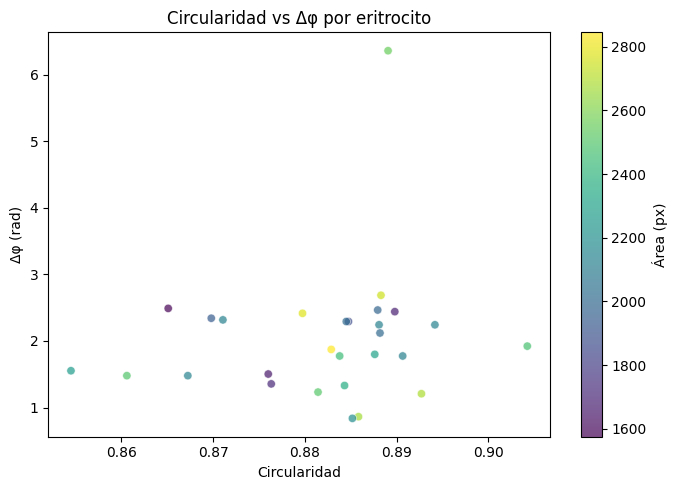

In [34]:
# Scatter: circularidad vs delta de fase
if len(df_int) > 0:
    fig, ax = plt.subplots(figsize=(7, 5))
    sc = ax.scatter(df_int['circularity'], df_int['delta_phi'],
                    c=df_int['area_px'], cmap='viridis', alpha=0.7, edgecolors='white', lw=0.5)
    plt.colorbar(sc, ax=ax, label='Área (px)')
    ax.set_xlabel('Circularidad')
    ax.set_ylabel('Δφ (rad)')
    ax.set_title('Circularidad vs Δφ por eritrocito')
    plt.tight_layout()
    fig.savefig(SAVE_DIR / 'circularity_vs_delta.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [35]:
# Guardar CSV de resultados
df_img.to_csv(SAVE_DIR / 'resultados_por_imagen.csv', index=False)
df_cell.to_csv(SAVE_DIR / 'resultados_por_celula.csv', index=False)
print(f'Resultados guardados en {SAVE_DIR}:')
for f in sorted(SAVE_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f'  {f.name}  ({size_kb:.1f} KB)')

Resultados guardados en /content/data/processed/heuristica_validacion:
  annotated_Image__2021-01-28__16-04-31_3-3.png  (481.9 KB)
  annotated_Image__2021-01-29__12-36-21_4-3.png  (489.8 KB)
  annotated_Image__2021-01-29__12-53-41_1-6.png  (577.0 KB)
  annotated_Image__2021-01-29__13-12-01_4-1.png  (496.8 KB)
  annotated_Image__2021-01-29__13-12-01_4-11.png  (428.5 KB)
  annotated_Image__2021-01-29__13-12-45_2-1.png  (475.0 KB)
  annotated_Image__2021-01-29__13-15-19_3-6.png  (669.6 KB)
  annotated_Image__2021-01-29__13-26-59_3-8.png  (533.9 KB)
  circularity_vs_delta.png  (46.8 KB)
  resultados_por_celula.csv  (5.3 KB)
  resultados_por_imagen.csv  (1.1 KB)
  resumen_delta_phi.png  (93.1 KB)


## 6. Copiar resultados a Drive

In [36]:
import shutil

DRIVE_OUT = Path('/content/drive/MyDrive/dl-qpi/data/processed/heuristica_validacion')
if DRIVE_OUT.exists():
    shutil.rmtree(DRIVE_OUT)
shutil.copytree(SAVE_DIR, DRIVE_OUT)
print(f'Resultados copiados a Drive: {DRIVE_OUT}')
for f in sorted(DRIVE_OUT.iterdir()):
    print(f'  {f.name}')

Resultados copiados a Drive: /content/drive/MyDrive/dl-qpi/data/processed/heuristica_validacion
  annotated_Image__2021-01-28__16-04-31_3-3.png
  annotated_Image__2021-01-29__12-36-21_4-3.png
  annotated_Image__2021-01-29__12-53-41_1-6.png
  annotated_Image__2021-01-29__13-12-01_4-1.png
  annotated_Image__2021-01-29__13-12-01_4-11.png
  annotated_Image__2021-01-29__13-12-45_2-1.png
  annotated_Image__2021-01-29__13-15-19_3-6.png
  annotated_Image__2021-01-29__13-26-59_3-8.png
  circularity_vs_delta.png
  resultados_por_celula.csv
  resultados_por_imagen.csv
  resumen_delta_phi.png


## Checklist de entrega (issue #8)

| Criterio | Estado |
|---|---|
| Segmenta eritrocitos individuales en ≥ 5 imágenes de fase | Listo :) |
| Calcula y grafica perfil de fase y $\Delta\phi$ por eritrocito | Realizado |
| Muestra reconstrucción visual de cada eritrocito individual | Hecho |
| Genera versión anotada con promedio de perfil/$\Delta\phi$ por imagen | Completo |